# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Muhammad Farid Wijdan | 5054251042 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

RANDOM_STATE = 42
print('Imports berhasil!')
print(f'pandas {pd.__version__} | numpy {np.__version__}')


Imports berhasil!
pandas 3.0.5 | numpy 2.5.3


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')
print(f'Bentuk dataset: {df.shape[0]} baris x {df.shape[1]} kolom')
print()
print('=== Tipe data (df.dtypes) ===')
print(df.dtypes)
print()
print('=== Head (5 baris pertama) ===')
display(df.head())
print()
print('=== Statistik deskriptif ===')
display(df.describe(include='all').T)
print()
print('=== Jumlah missing value per kolom ===')
print(df.isna().sum())
print()
print('=== Jumlah baris duplikat ===')
print(f'Duplikat seluruh baris: {df.duplicated().sum()} | Duplikat status_id: {df.duplicated(subset=["status_id"]).sum()}')
print()
print('Kolom yang seluruhnya kosong:')
print(df.columns[df.isna().all()].tolist())


Bentuk dataset: 7050 baris x 16 kolom

=== Tipe data (df.dtypes) ===
status_id             int64
status_type             str
status_published        str
num_reactions         int64
num_comments          int64
num_shares            int64
num_likes             int64
num_loves             int64
num_wows              int64
num_hahas             int64
num_sads              int64
num_angrys            int64
Column1             float64
Column2             float64
Column3             float64
Column4             float64
dtype: object

=== Head (5 baris pertama) ===


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN



=== Statistik deskriptif ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
status_id,7050.0,NaN,NaN,NaN,3525.5,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
status_type,7050,4,photo,4288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status_published,7050,6913,3/20/2018 1:54,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_reactions,7050.0,NaN,NaN,NaN,230.117163,462.625309,0.0,17.0,59.5,219.0,4710.0
num_comments,7050.0,NaN,NaN,NaN,224.356028,889.63682,0.0,0.0,4.0,23.0,20990.0
num_shares,7050.0,NaN,NaN,NaN,40.022553,131.599965,0.0,0.0,0.0,4.0,3424.0
num_likes,7050.0,NaN,NaN,NaN,215.043121,449.472357,0.0,17.0,58.0,184.75,4710.0
num_loves,7050.0,NaN,NaN,NaN,12.728652,39.97293,0.0,0.0,0.0,3.0,657.0
num_wows,7050.0,NaN,NaN,NaN,1.289362,8.71965,0.0,0.0,0.0,0.0,278.0
num_hahas,7050.0,NaN,NaN,NaN,0.696454,3.957183,0.0,0.0,0.0,0.0,157.0



=== Jumlah missing value per kolom ===
status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

=== Jumlah baris duplikat ===
Duplikat seluruh baris: 0 | Duplikat status_id: 0

Kolom yang seluruhnya kosong:
['Column1', 'Column2', 'Column3', 'Column4']


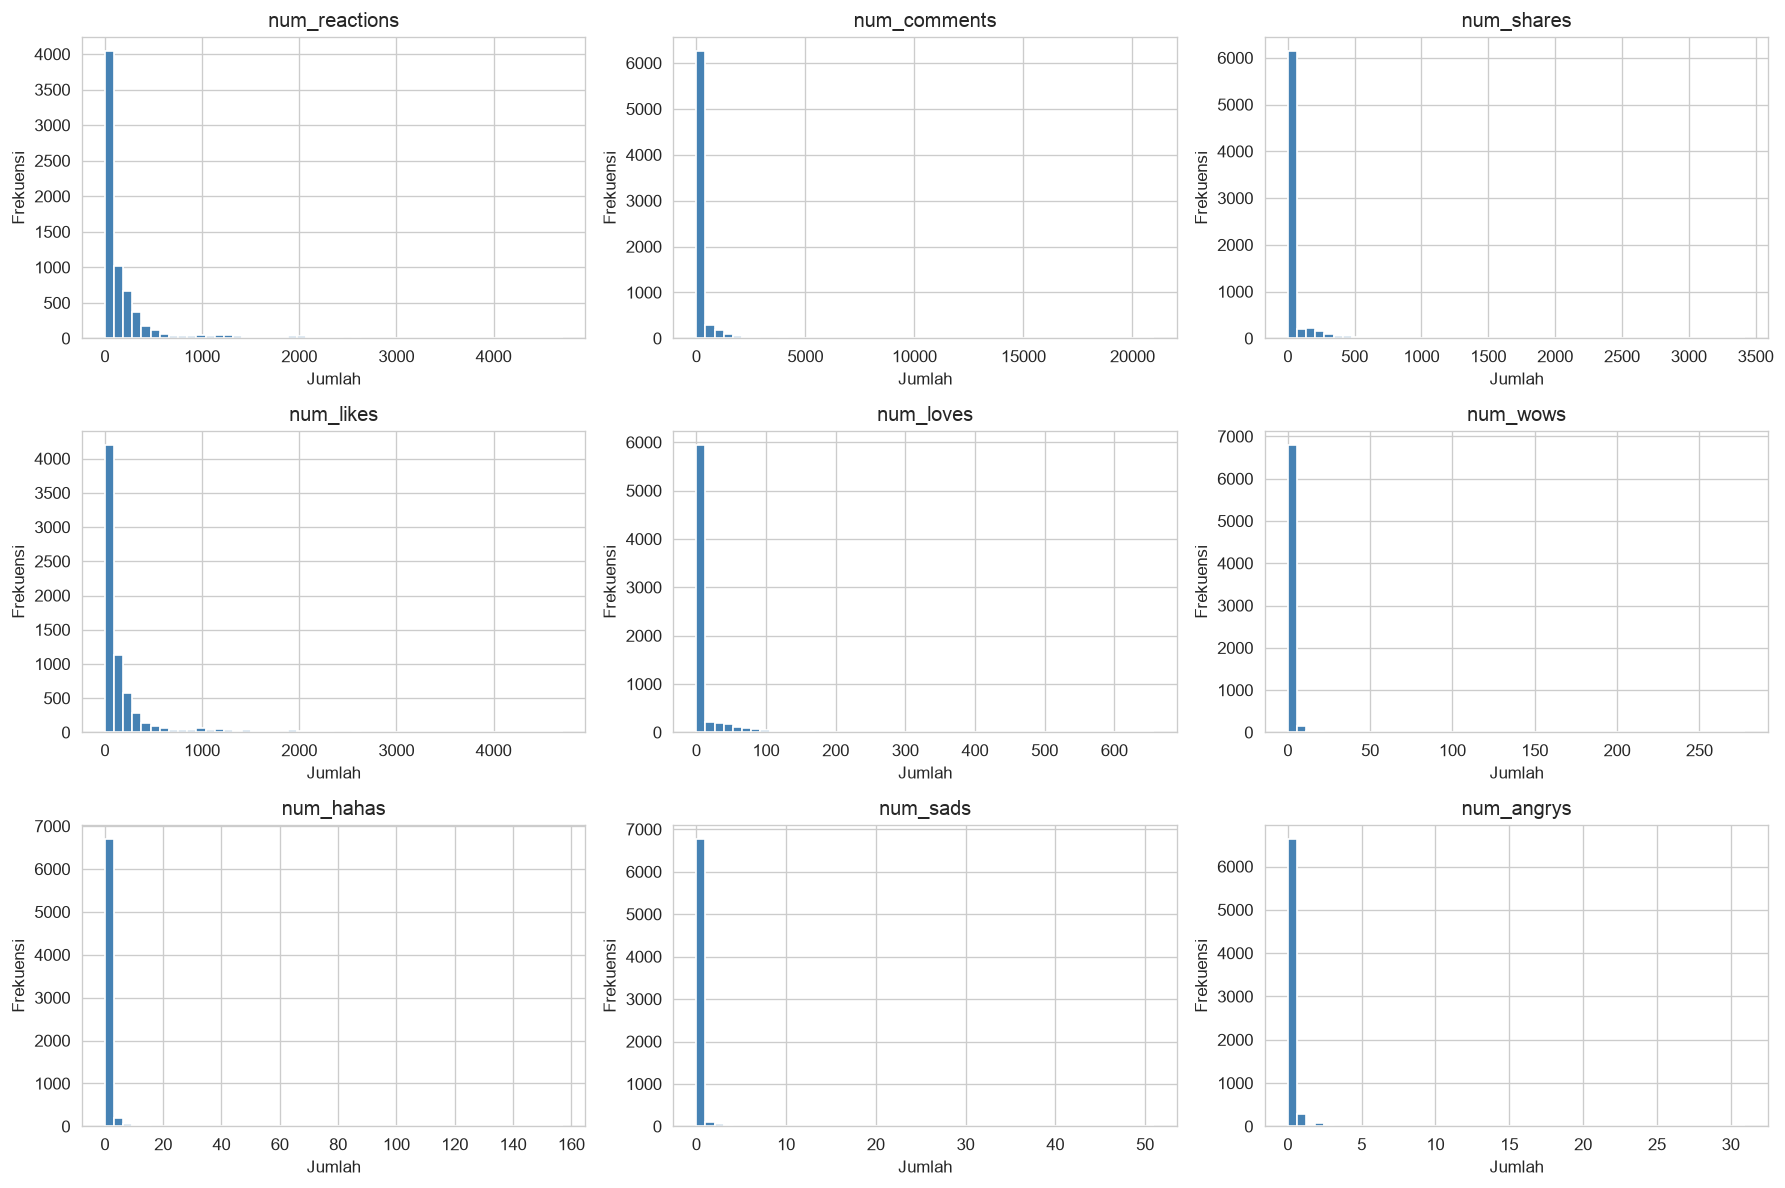

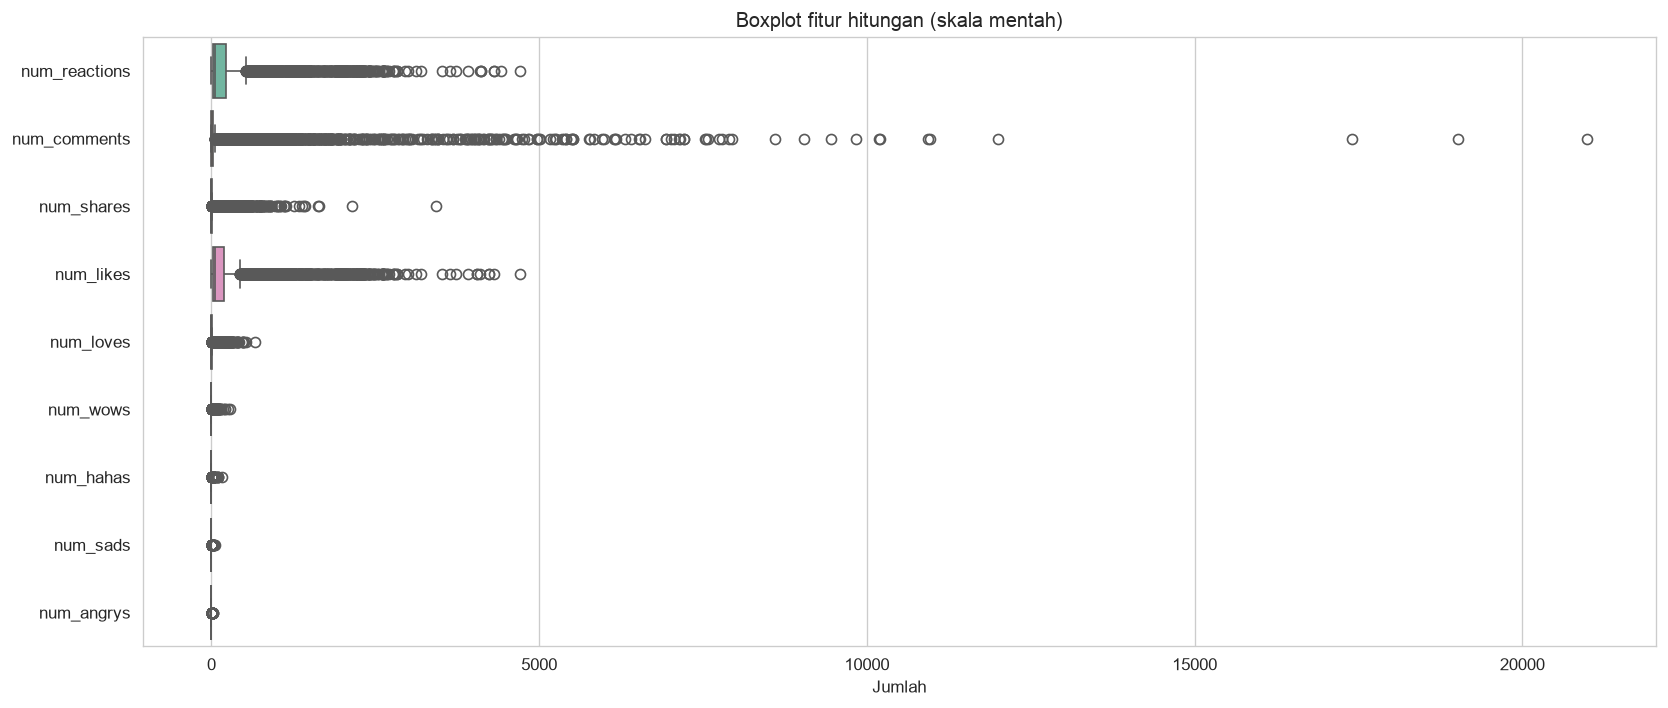

=== Skewness dan proporsi nol ===


,skewness,proporsi_nol,median,mean,max
num_reactions,3.738,0.017,59.5,230.117,4710
num_comments,9.029,0.301,4.0,224.356,20990
num_shares,7.099,0.555,0.0,40.023,3424
num_likes,3.919,0.018,58.0,215.043,4710
num_loves,6.005,0.600,0.0,12.729,657
num_wows,18.247,0.753,0.0,1.289,278
num_hahas,20.306,0.839,0.0,0.696,157
num_sads,17.579,0.914,0.0,0.244,51
num_angrys,19.507,0.940,0.0,0.113,31


Observasi: semua fitur sangat right-skewed (skewness > 3); num_comments max 21.000-an vs num_angrys max 31.


In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
feat_cols_all = ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, feat_cols_all):
    ax.hist(df[col], bins=50, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Jumlah')
    ax.set_ylabel('Frekuensi')
plt.tight_layout()
plt.show()

# Boxplot untuk melihat outlier ekstrem (skala sangat berbeda antar fitur)
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df[feat_cols_all], orient='h', palette='Set2')
plt.title('Boxplot fitur hitungan (skala mentah)')
plt.xlabel('Jumlah')
plt.tight_layout()
plt.show()

print('=== Skewness dan proporsi nol ===')
ringkasan = pd.DataFrame({
    'skewness': df[feat_cols_all].skew(),
    'proporsi_nol': (df[feat_cols_all] == 0).mean(),
    'median': df[feat_cols_all].median(),
    'mean': df[feat_cols_all].mean(),
    'max': df[feat_cols_all].max(),
})
display(ringkasan.round(3))
print('Observasi: semua fitur sangat right-skewed (skewness > 3); num_comments max 21.000-an vs num_angrys max 31.')


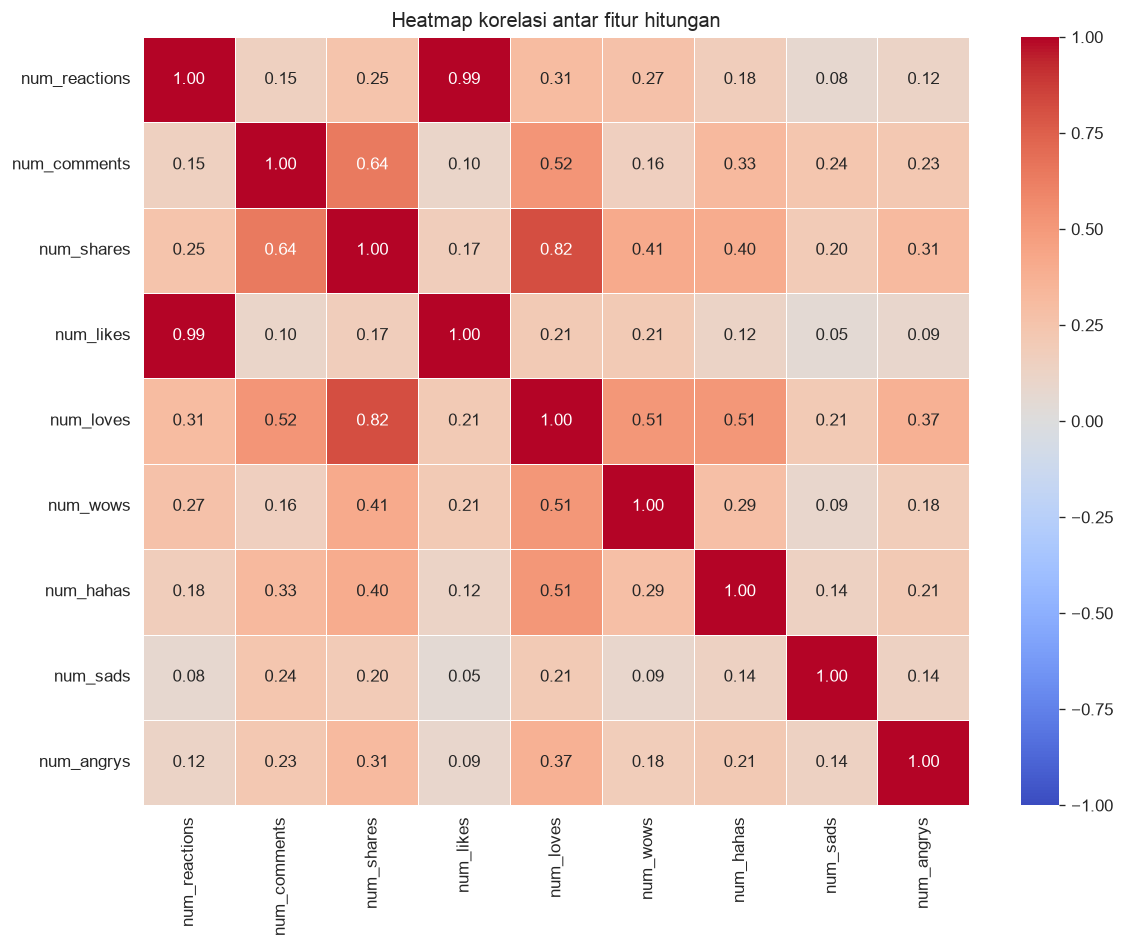

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
num_reactions,1.00,0.15,0.25,0.99,0.31,0.27,0.18,0.08,0.12
num_comments,0.15,1.00,0.64,0.10,0.52,0.16,0.33,0.24,0.23
num_shares,0.25,0.64,1.00,0.17,0.82,0.41,0.40,0.20,0.31
num_likes,0.99,0.10,0.17,1.00,0.21,0.21,0.12,0.05,0.09
num_loves,0.31,0.52,0.82,0.21,1.00,0.51,0.51,0.21,0.37
num_wows,0.27,0.16,0.41,0.21,0.51,1.00,0.29,0.09,0.18
num_hahas,0.18,0.33,0.40,0.12,0.51,0.29,1.00,0.14,0.21
num_sads,0.08,0.24,0.20,0.05,0.21,0.09,0.14,1.00,0.14
num_angrys,0.12,0.23,0.31,0.09,0.37,0.18,0.21,0.14,1.00


Korelasi num_reactions vs num_likes: 0.99 (redundan, definisi saling tumpang tindih).
Korelasi num_comments vs num_shares: 0.64; num_loves vs num_shares: 0.82.


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
corr = df[feat_cols_all].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap korelasi antar fitur hitungan')
plt.tight_layout()
plt.show()
display(corr.round(2))
print(f"Korelasi num_reactions vs num_likes: {df['num_reactions'].corr(df['num_likes']):.2f} (redundan, definisi saling tumpang tindih).")
print(f"Korelasi num_comments vs num_shares: {df['num_comments'].corr(df['num_shares']):.2f}; num_loves vs num_shares: {df['num_loves'].corr(df['num_shares']):.2f}.")


Periode data: 2012-07-15 02:51:00 s.d. 2018-06-13 01:12:00
Jumlah baris ter-parse datetime: 7050 / 7050

=== Jumlah posting per tahun ===
tahun
2012     589
2013     500
2014     233
2015     337
2016     588
2017    2253
2018    2550
dtype: int64

=== Proporsi posting dengan reaksi emoji per tahun ===
tahun
2012    0.000
2013    0.000
2014    0.000
2015    0.000
2016    0.680
2017    0.542
2018    0.578
Name: emoji_any, dtype: float64


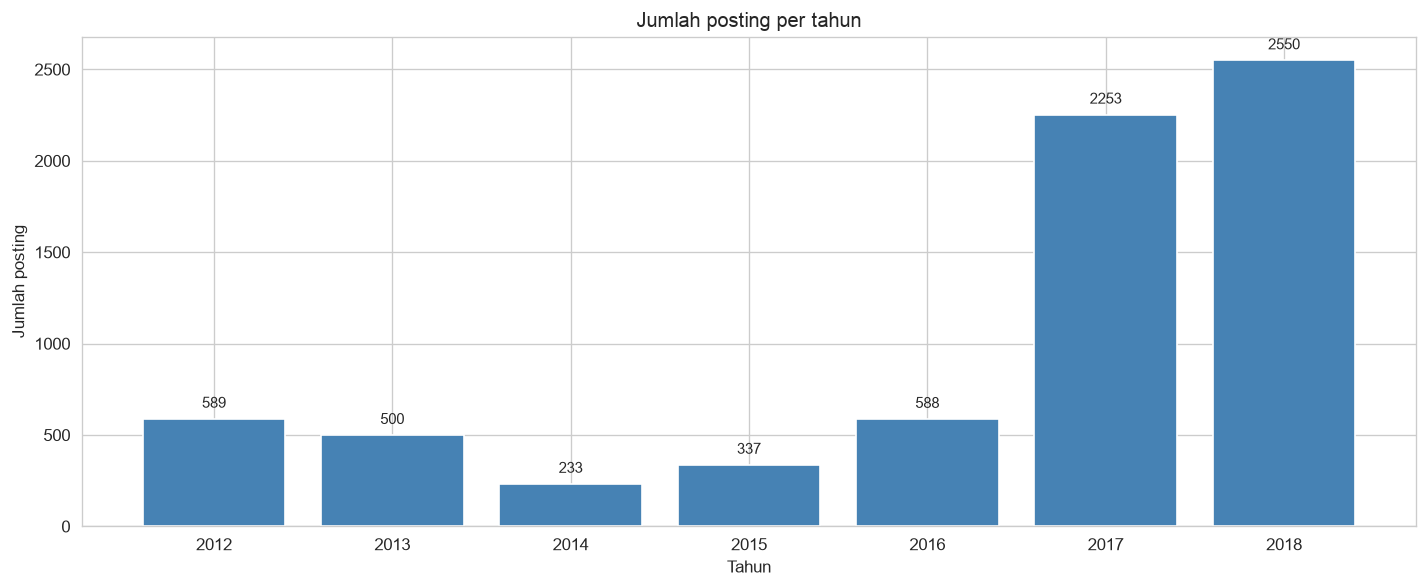

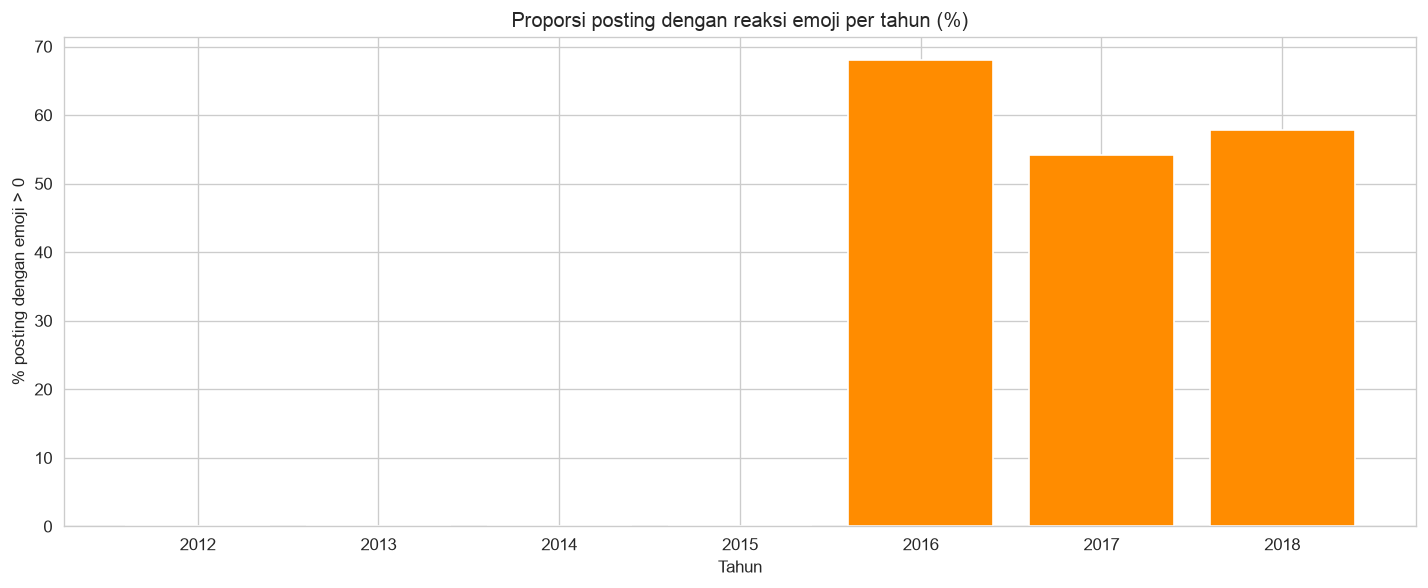

Observasi: nol emoji sebelum 2016 (reaksi emoji baru tersedia sejak 2016); mulai 2016 proporsi posting ber-emoji sekitar 54-68%.


In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'])
print(f"Periode data: {df['status_published'].min()} s.d. {df['status_published'].max()}")
print(f"Jumlah baris ter-parse datetime: {df['status_published'].notna().sum()} / {len(df)}")

df['tahun'] = df['status_published'].dt.year
df['emoji_any'] = (df[['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1) > 0)

posting_per_tahun = df.groupby('tahun').size()
prop_emoji = df.groupby('tahun')['emoji_any'].mean()

print()
print('=== Jumlah posting per tahun ===')
print(posting_per_tahun)
print()
print('=== Proporsi posting dengan reaksi emoji per tahun ===')
print(prop_emoji.round(3))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(posting_per_tahun.index.astype(str), posting_per_tahun.values, color='steelblue')
ax.set_title('Jumlah posting per tahun')
ax.set_xlabel('Tahun')
ax.set_ylabel('Jumlah posting')
for i, v in enumerate(posting_per_tahun.values):
    ax.text(i, v + 60, str(v), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(prop_emoji.index.astype(str), (prop_emoji.values * 100).round(1), color='darkorange')
ax.set_title('Proporsi posting dengan reaksi emoji per tahun (%)')
ax.set_xlabel('Tahun')
ax.set_ylabel('% posting dengan emoji > 0')
plt.tight_layout()
plt.show()
print('Observasi: nol emoji sebelum 2016 (reaksi emoji baru tersedia sejak 2016); mulai 2016 proporsi posting ber-emoji sekitar 54-68%.')


status_type
photo     4288
video     2334
status     365
link        63
Name: count, dtype: int64


/var/folders/1w/yqznhsk91cggg4l67976h2tw0000gn/T/ipykernel_94165/2095485589.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status_type', data=df, palette='Set2', order=df['status_type'].value_counts().index)


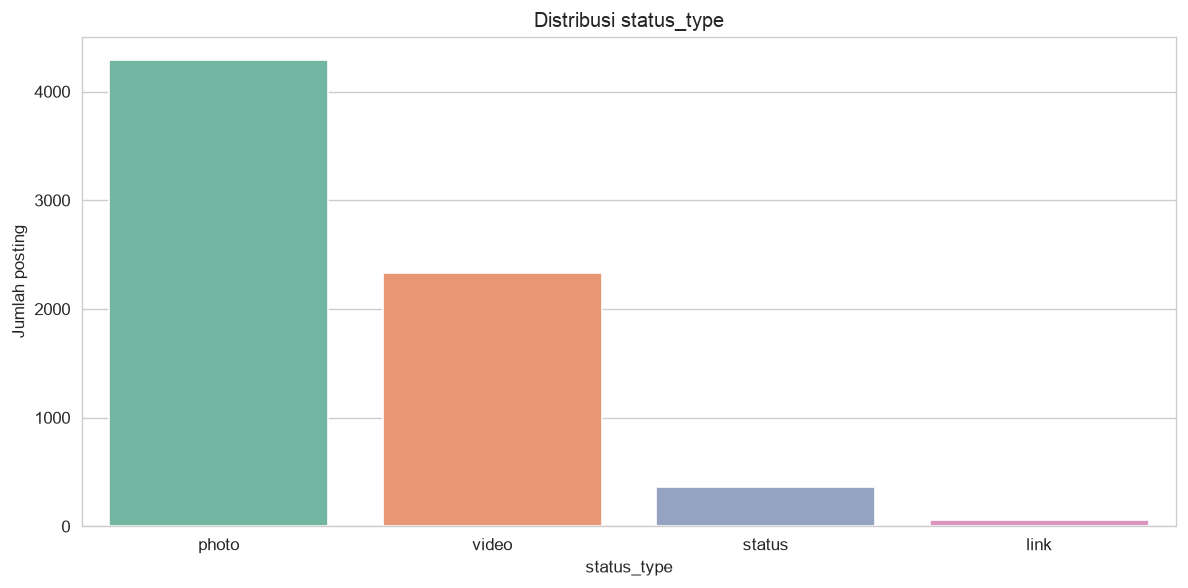


=== Median engagement per status_type ===


,num_likes,num_comments,num_shares,num_reactions
status_type,,,,
link,48.0,1.0,0.0,50.0
photo,34.0,2.0,0.0,34.0
status,117.0,10.0,0.0,120.0
video,117.0,39.0,12.0,160.0


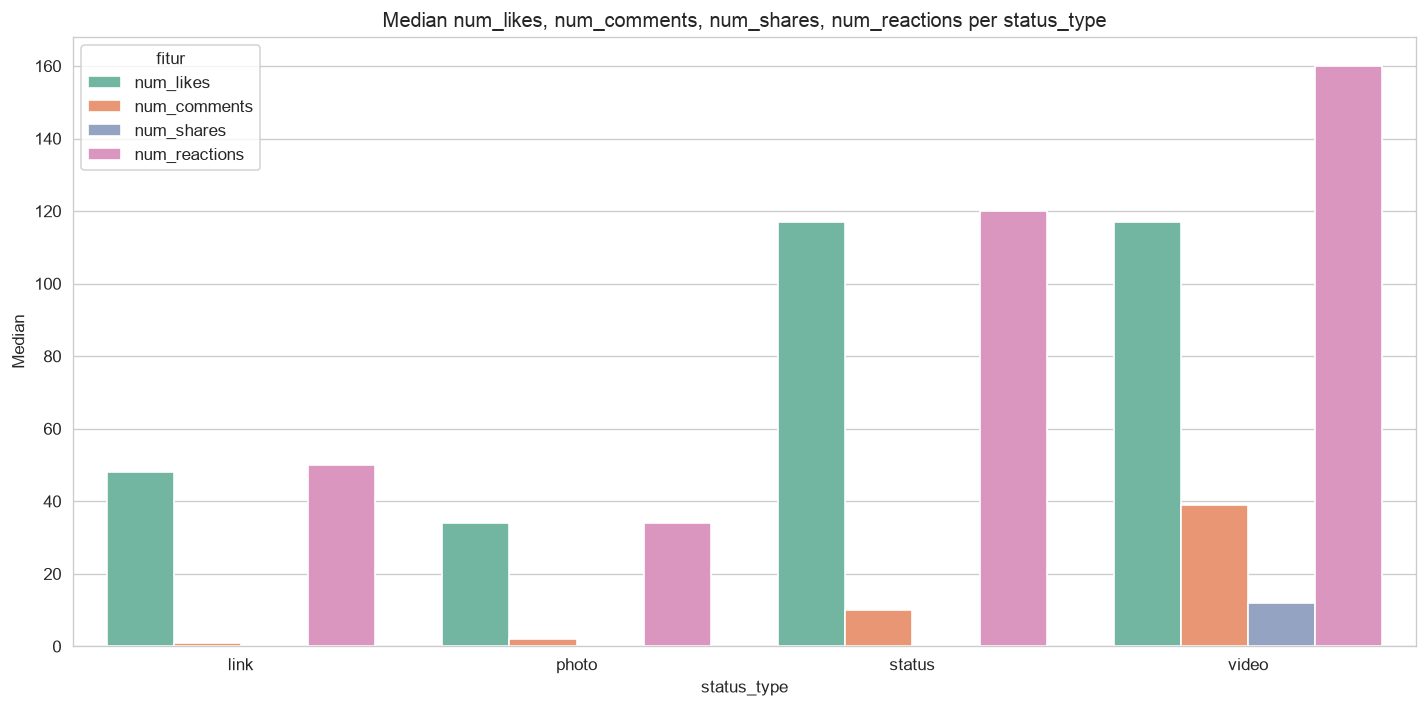

Observasi: video median komentar & share jauh lebih tinggi; photo dominan di dataset (4.288 posting).


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
print(df['status_type'].value_counts())
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(x='status_type', data=df, palette='Set2', order=df['status_type'].value_counts().index)
ax.set_title('Distribusi status_type')
ax.set_xlabel('status_type')
ax.set_ylabel('Jumlah posting')
plt.tight_layout()
plt.show()

median_per_type = df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares', 'num_reactions']].median()
print()
print('=== Median engagement per status_type ===')
display(median_per_type)
fig, ax = plt.subplots(figsize=(12, 6))
melted = median_per_type.reset_index().melt(id_vars='status_type', var_name='fitur', value_name='median')
sns.barplot(data=melted, x='status_type', y='median', hue='fitur', palette='Set2')
ax.set_title('Median num_likes, num_comments, num_shares, num_reactions per status_type')
ax.set_ylabel('Median')
plt.tight_layout()
plt.show()
print('Observasi: video median komentar & share jauh lebih tinggi; photo dominan di dataset (4.288 posting).')


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Selain EDA wajib di sel 4-7 (distribusi, korelasi, tahun, dan status_type), dilakukan EDA tambahan berikut untuk memastikan keputusan preprocessing dan pilihan fitur tidak salah arah:

- **Outlier ekstrem:** `num_comments` max 20.990 (video) dan `num_reactions` max 4.710 (photo) dengan persentil-99 jauh di bawah max, serta batas IQR menghasilkan ratusan outlier per fitur hitungan. Artinya ada posting viral tulen yang bukan kesalahan data. Keputusan: tidak menghapus outlier; menanganinya dengan `log1p` agar centroid tidak ditarik segelondong oleh beberapa posting viral.
- **Pergeseran temporal:** median `num_likes` per tahun sangat tidak stabil — 2014 (437) dan 2015 (1.566) jauh lebih tinggi dibanding 2017 (41) dan 2018 (54,5), sementara jumlah posting justru menumpuk di 2017 (2.253) dan 2018 (2.550). Reaksi emoji nol total sebelum 2016 (fitur belum ada). Artinya dimensi waktu membawa perubahan konteks engagement, tetapi kolom waktu tidak dipakai sebagai fitur clustering (sesuai tugas); dampaknya dibahas sebagai faktor perancu pada analisis dan saran (clustering terpisah pra/pasca-2016).
- **Ketergantungan antar fitur:** korelasi `num_reactions` vs `num_likes` 0,99 menunjukkan `num_reactions` hampir sama dengan `num_likes` (sudah mencakup like). `num_shares` berkorelasi 0,82 dengan `num_loves` dan 0,64 dengan `num_comments`, jadi share/komentar/love memang menumpuk pada posting viral yang sama — tetapi masih masing-masing membawa sisi berbeda (distribusi vs percakapan vs apresiasi) sehingga dipertahankan secara terpisah setelah reduksi redundansi utama.
- **Sparsity emoji:** hanya 43,9% posting yang memiliki setidaknya satu emoji; `num_sads` 91,4% nol dan `num_angrys` 94,0% nol membuat dimensi-dimension tersebut hampir konstan. Ini memperkuat keputusan menggabungkan empat emoji langka menjadi `num_emoji_other` (lihat markdown di Bagian 2) agar clustering tidak menghabiskan energi pada dimensi yang nyaris tidak bervariasi.

Kesimpulan EDA tambahan: data cocok untuk pendekatan `log1p + StandardScaler` pada 5 fitur engagement yang sudah dipadatkan, dengan pemisahan jelas antara viral-tinggi dan sepi-rendah yang diharapkan muncul sebagai cluster.


# 2. Preprocessing

In [7]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
kolom_kosong = df.columns[df.isna().all()].tolist()
print(f'Kolom yang seluruhnya kosong: {kolom_kosong}')
df = df.drop(columns=kolom_kosong)
print(f'Bentuk setelah drop kolom kosong: {df.shape}')

# Periksa duplikat: status_id selalu unik
print(f"Duplikat status_id: {df.duplicated(subset=['status_id']).sum()}")
print(f"Duplikat seluruh baris: {df.duplicated().sum()}")
print('Tidak ada duplikat, jadi tidak ada baris yang dihapus pada langkah ini.')

# Missing value tersisa
print()
print('=== Missing value setelah drop kolom kosong ===')
print(df.isna().sum())
print(f"Total missing value: {df.isna().sum().sum()} -> tidak ada imputasi yang diperlukan.")

# Outlier ekstrem: cek max, persentil 99, dan jumlah di luar Q3+1.5*IQR
feat_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
q1 = df[feat_cols].quantile(0.25)
q3 = df[feat_cols].quantile(0.75)
iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr
outlier_counts = (df[feat_cols] > batas_atas).sum()
outlier_df = pd.DataFrame({'max': df[feat_cols].max(), 'p99': df[feat_cols].quantile(0.99), 'batas_IQR': batas_atas, 'n_outlier_IQR': outlier_counts})
display(outlier_df.round(1))
print('Penanganan outlier: TIDAK dihapus (outlier adalah posting viral yang informatif); ditangani lewat log1p + StandardScaler di langkah berikutnya.')
print(f"Contoh ekstrem: max num_comments={df['num_comments'].max():,.0f} (video), max num_reactions={df['num_reactions'].max():,.0f} (photo).")


Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']
Bentuk setelah drop kolom kosong: (7050, 14)
Duplikat status_id: 0
Duplikat seluruh baris: 0
Tidak ada duplikat, jadi tidak ada baris yang dihapus pada langkah ini.

=== Missing value setelah drop kolom kosong ===
status_id           0
status_type         0
status_published    0
num_reactions       0
num_comments        0
num_shares          0
num_likes           0
num_loves           0
num_wows            0
num_hahas           0
num_sads            0
num_angrys          0
tahun               0
emoji_any           0
dtype: int64
Total missing value: 0 -> tidak ada imputasi yang diperlukan.


,max,p99,batas_IQR,n_outlier_IQR
num_reactions,4710,2306.1,522.0,705
num_comments,20990,4338.0,57.5,1374
num_shares,3424,607.0,10.0,1393
num_likes,4710,2297.0,436.4,774
num_loves,657,198.0,7.5,1323
num_wows,278,16.0,0.0,1742
num_hahas,157,12.0,0.0,1134
num_sads,51,5.0,0.0,607
num_angrys,31,3.0,0.0,423


Penanganan outlier: TIDAK dihapus (outlier adalah posting viral yang informatif); ditangani lewat log1p + StandardScaler di langkah berikutnya.
Contoh ekstrem: max num_comments=20,990 (video), max num_reactions=4,710 (photo).


In [8]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
df_eval = df[['status_type', 'status_published']].copy()
print(f"df_eval (untuk interpretasi): shape {df_eval.shape}")
print(df_eval.head(3).to_string())

print(f"status_id unik: {df['status_id'].nunique()} / {len(df)} nilai (ID, bukan fitur engagement) -> dihapus dari clustering.")

# Redundansi
print()
print('=== Redundansi ===')
print(f"Korelasi num_reactions - num_likes: {df['num_reactions'].corr(df['num_likes']):.3f}")
print(f"Korelasi num_loves - num_shares: {df['num_loves'].corr(df['num_shares']):.3f}")

# Sparsity: proporsi nol
print()
print('=== Proporsi nol per fitur (sparsity) ===')
print(((df[feat_cols] == 0).mean() * 100).round(1).to_string())

# Gabungkan fitur emoji yang sparse menjadi num_emoji_other; num_loves disimpan terpisah
df['num_emoji_other'] = df['num_wows'] + df['num_hahas'] + df['num_sads'] + df['num_angrys']
print(f"num_emoji_other: proporsi nol = {(df['num_emoji_other'] == 0).mean():.3f} (vs num_sads {(df['num_sads'] == 0).mean():.3f}, num_angrys {(df['num_angrys'] == 0).mean():.3f})")
print(f"num_emoji_other max = {df['num_emoji_other'].max()}, median = {df['num_emoji_other'].median()}")

final_features = ['num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_emoji_other']
print(f"Fitur final untuk clustering ({len(final_features)} fitur): {final_features}")
print('Fitur yang dibuang: num_reactions (redundan), num_wows/num_hahas/num_sads/num_angrys (digabung), status_id, status_type, status_published, emoji_any, tahun')

X_raw_df = df[final_features].copy()
print(f"X_raw_df shape: {X_raw_df.shape}")
display(X_raw_df.head())
display(X_raw_df.describe().T.round(2))


df_eval (untuk interpretasi): shape (7050, 2)
  status_type    status_published
0       video 2018-04-22 06:00:00
1       photo 2018-04-21 22:45:00
2       video 2018-04-21 06:17:00
status_id unik: 7050 / 7050 nilai (ID, bukan fitur engagement) -> dihapus dari clustering.

=== Redundansi ===
Korelasi num_reactions - num_likes: 0.995
Korelasi num_loves - num_shares: 0.820

=== Proporsi nol per fitur (sparsity) ===
num_reactions     1.7
num_comments     30.1
num_shares       55.5
num_likes         1.8
num_loves        60.0
num_wows         75.3
num_hahas        83.9
num_sads         91.4
num_angrys       94.0
num_emoji_other: proporsi nol = 0.685 (vs num_sads 0.914, num_angrys 0.940)
num_emoji_other max = 286, median = 0.0
Fitur final untuk clustering (5 fitur): ['num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_emoji_other']
Fitur yang dibuang: num_reactions (redundan), num_wows/num_hahas/num_sads/num_angrys (digabung), status_id, status_type, status_published, emoji_any, tah

,num_comments,num_shares,num_likes,num_loves,num_emoji_other
0,512,262,432,92,5
1,0,0,150,0,0
2,236,57,204,21,2
3,0,0,111,0,0
4,0,0,204,9,0


,count,mean,std,min,25%,50%,75%,max
num_comments,7050.0,224.36,889.64,0.0,0.0,4.0,23.00,20990.0
num_shares,7050.0,40.02,131.60,0.0,0.0,0.0,4.00,3424.0
num_likes,7050.0,215.04,449.47,0.0,17.0,58.0,184.75,4710.0
num_loves,7050.0,12.73,39.97,0.0,0.0,0.0,3.00,657.0
num_emoji_other,7050.0,2.34,11.08,0.0,0.0,0.0,1.00,286.0


**Fitur yang dipilih untuk clustering:**

Fitur final (5 fitur, semuanya numerik): `num_comments`, `num_shares`, `num_likes`, `num_loves`, `num_emoji_other`.
`num_emoji_other = num_wows + num_hahas + num_sads + num_angrys` adalah gabungan emoji yang sparse.

Alasan pemilihan:

- `status_id` dibuang: identifier unik untuk tiap posting (7.050 nilai unik), bukan ukuran engagement, sehingga tidak boleh memengaruhi jarak antar posting.
- `status_type` dan `status_published` dipisahkan ke `df_eval` untuk interpretasi/evaluasi saja. Keduanya tidak dipakai sebagai fitur clustering: `status_type` kategorikal dan memang dilarang dipakai sebagai fitur, sedangkan `status_published` adalah waktu posting, bukan engagement.
- `num_reactions` dibuang: redundan dengan `num_likes` (korelasi Pearson r = 0,99; `num_reactions` secara definisi sudah mencakup `num_likes` plus reaksi-emoji). Menyimpan keduanya berarti menghitung komponen "like/reaksi" dua kali dan menggandakan bobotnya dalam jarak Euclidean.
- Fitur emoji yang sebagian besar bernilai nol digabung: `num_wows` 75,3% nol, `num_hahas` 83,9% nol, `num_sads` 91,4% nol, `num_angrys` 94,0% nol. Empat kolom hampir-konstan ini digabung menjadi `num_emoji_other` (proporsi nol turun menjadi 68,5%, max 286) agar tidak menambah noise dan tidak membuat centroid ditarik oleh empat dimensi yang hampir selalu nol. `num_loves` disimpan terpisah karena hanya 60,0% nol dan merupakan satu-satunya emoji dengan sinyal cukup kuat untuk dibedakan.
- Hasilnya 9 kolom hitungan mentah dipadatkan menjadi 5 kolom: komentar, share, like, love, dan emoji lain-lain. Semua sudah numerik (syarat jarak-based clustering) dan masing-masing menangkap sisi engagement yang berbeda: percakapan (`num_comments`), distribusi (`num_shares`), apresiasi umum (`num_likes`), apresiasi positif (`num_loves`), dan reaksi lain (`num_emoji_other`).


=== Skewness sebelum vs sesudah log1p ===
                 sebelum_log1p  sesudah_log1p
num_comments             9.029          1.038
num_shares               7.099          1.526
num_likes                3.919         -0.014
num_loves                6.005          1.504
num_emoji_other         13.882          1.941


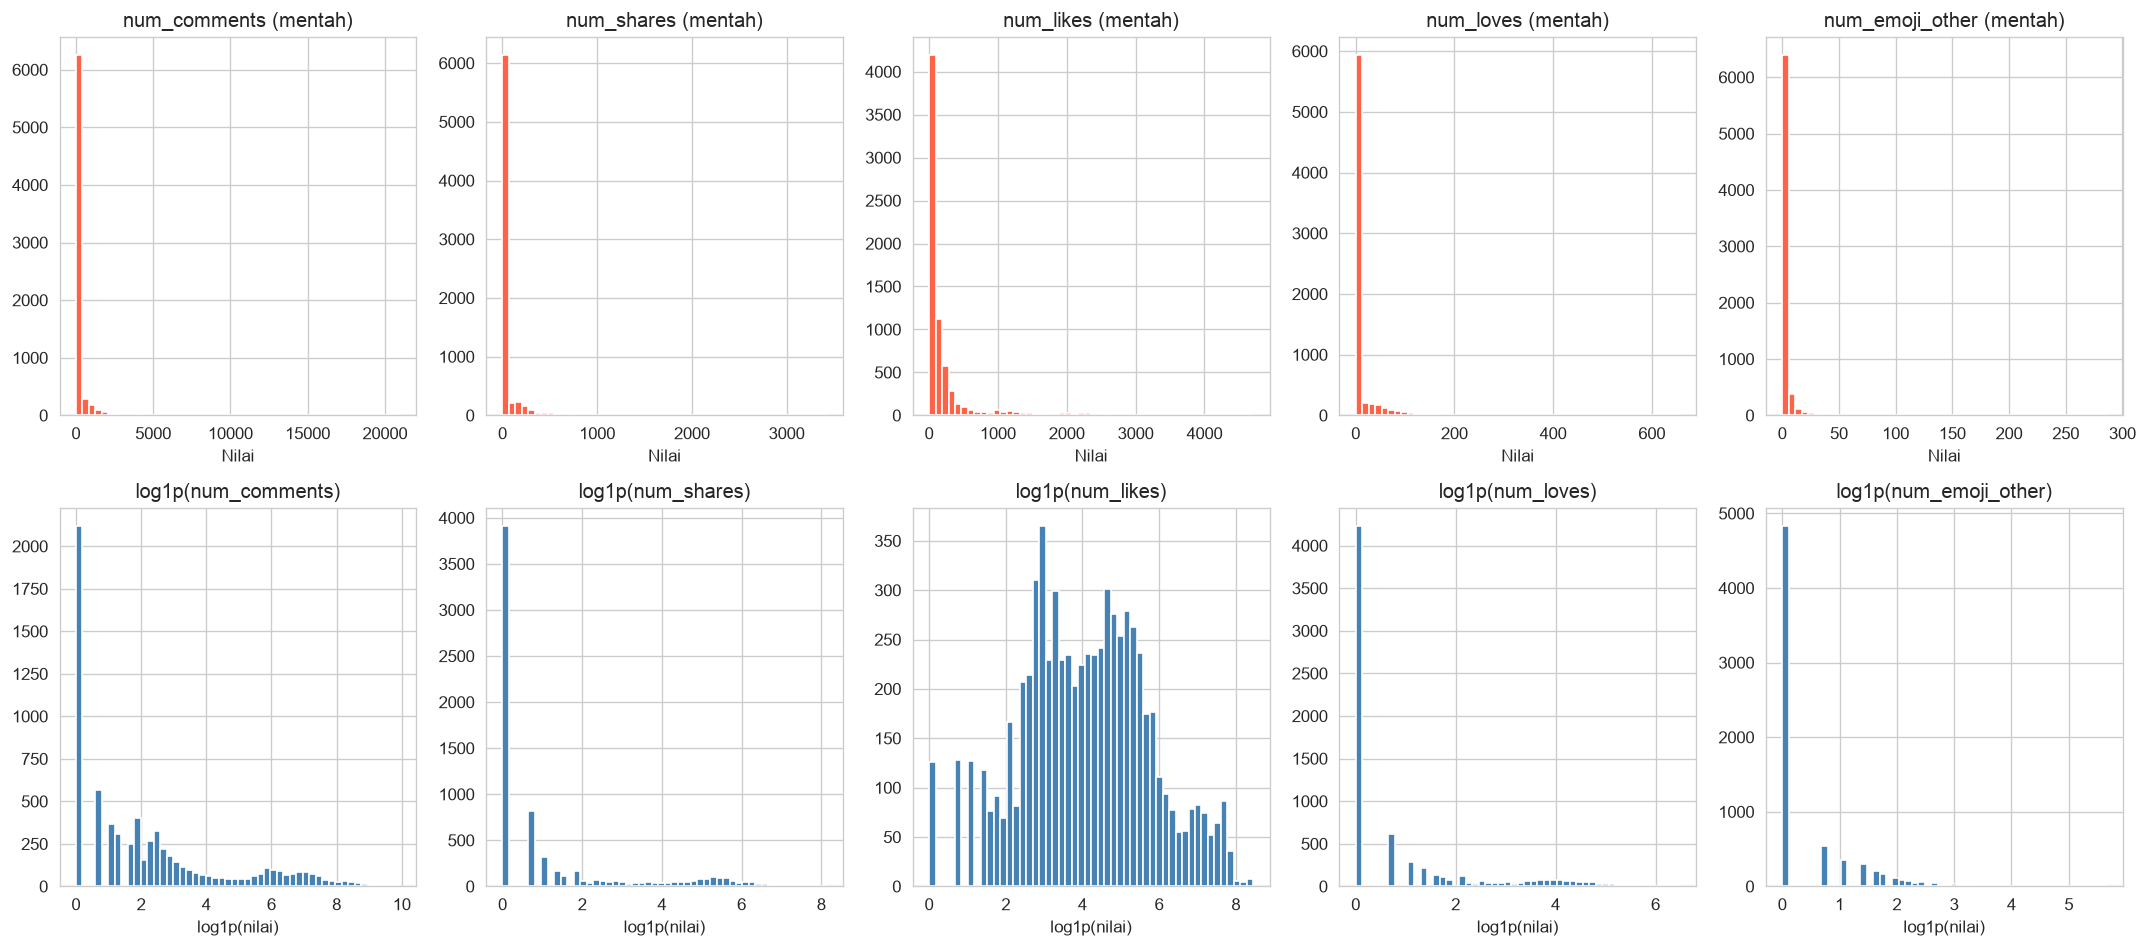

Observasi: sebelum log1p ekor kanan ekstrem (mis. num_comments skewness ~9,0); sesudah log1p distribusi jauh lebih simetris dan tidak didominasi outlier.


,count,mean,std,min,25%,50%,75%,max
num_comments,7050.0,2.223,2.336,0.0,0.00,1.609,3.178,9.952
num_shares,7050.0,1.210,1.885,0.0,0.00,0.000,1.609,8.139
num_likes,7050.0,4.062,1.691,0.0,2.89,4.078,5.224,8.458
num_loves,7050.0,0.953,1.497,0.0,0.00,0.000,1.386,6.489
num_emoji_other,7050.0,0.499,0.875,0.0,0.00,0.000,0.693,5.659


In [9]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log_df = np.log1p(X_raw_df)

print('=== Skewness sebelum vs sesudah log1p ===')
print(pd.DataFrame({'sebelum_log1p': X_raw_df.skew(), 'sesudah_log1p': X_log_df.skew()}).round(3).to_string())

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, col in zip(axes[0], final_features):
    ax.hist(X_raw_df[col], bins=50, color='tomato', edgecolor='white')
    ax.set_title(f'{col} (mentah)')
    ax.set_xlabel('Nilai')
for ax, col in zip(axes[1], final_features):
    ax.hist(X_log_df[col], bins=50, color='steelblue', edgecolor='white')
    ax.set_title(f'log1p({col})')
    ax.set_xlabel('log1p(nilai)')
plt.tight_layout()
plt.show()

print('Observasi: sebelum log1p ekor kanan ekstrem (mis. num_comments skewness ~9,0); sesudah log1p distribusi jauh lebih simetris dan tidak didominasi outlier.')
display(X_log_df.describe().T.round(3))


In [10]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1: X_raw dan X_raw_scaled.
X_raw = X_raw_df.to_numpy()
X_log = np.log1p(X_raw_df.to_numpy())

scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(X_log)

scaler_raw = StandardScaler()
X_raw_scaled = scaler_raw.fit_transform(X_raw)

print(f'X_raw shape: {X_raw.shape} (tanpa transformasi dan tanpa scaling)')
print(f'X_raw_scaled shape: {X_raw_scaled.shape} (mentah dengan scaling saja)')
print(f'X_log_scaled shape: {X_log_scaled.shape} (log1p + scaling)')

print()
print('=== Statistik X_log_scaled (harus mean ~0, std ~1 per fitur) ===')
print(pd.DataFrame(X_log_scaled, columns=final_features).describe().T[['mean', 'std', 'min', 'max']].round(3).to_string())
print(f"Mean scaler_log: {dict(zip(final_features, np.round(scaler_log.mean_, 3)))}")
print(f"Scale scaler_log: {dict(zip(final_features, np.round(scaler_log.scale_, 3)))}")


X_raw shape: (7050, 5) (tanpa transformasi dan tanpa scaling)
X_raw_scaled shape: (7050, 5) (mentah dengan scaling saja)
X_log_scaled shape: (7050, 5) (log1p + scaling)

=== Statistik X_log_scaled (harus mean ~0, std ~1 per fitur) ===
                 mean  std    min    max
num_comments      0.0  1.0 -0.951  3.309
num_shares       -0.0  1.0 -0.642  3.675
num_likes        -0.0  1.0 -2.402  2.600
num_loves         0.0  1.0 -0.637  3.699
num_emoji_other   0.0  1.0 -0.570  5.901
Mean scaler_log: {'num_comments': np.float64(2.223), 'num_shares': np.float64(1.21), 'num_likes': np.float64(4.062), 'num_loves': np.float64(0.953), 'num_emoji_other': np.float64(0.499)}
Scale scaler_log: {'num_comments': np.float64(2.336), 'num_shares': np.float64(1.885), 'num_likes': np.float64(1.691), 'num_loves': np.float64(1.497), 'num_emoji_other': np.float64(0.874)}


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [11]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data: (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
k_banding = 3
km_raw = KMeans(n_clusters=k_banding, random_state=RANDOM_STATE, n_init=10).fit(X_raw)
km_raw_scaled = KMeans(n_clusters=k_banding, random_state=RANDOM_STATE, n_init=10).fit(X_raw_scaled)
km_log_scaled = KMeans(n_clusters=k_banding, random_state=RANDOM_STATE, n_init=10).fit(X_log_scaled)

print(f'KMeans k={k_banding} dengan random_state={RANDOM_STATE}, n_init=10 (sama untuk ketiga versi agar perbandingan adil).')
for nama, km in [('X_raw', km_raw), ('X_raw_scaled', km_raw_scaled), ('X_log_scaled', km_log_scaled)]:
    print(f"{nama}: inertia={km.inertia_:.1f}, jumlah anggota per cluster (diurutkan terbesar)={sorted(pd.Series(km.labels_).value_counts().tolist(), reverse=True)}")


KMeans k=3 dengan random_state=42, n_init=10 (sama untuk ketiga versi agar perbandingan adil).
X_raw: inertia=2387963332.9, jumlah anggota per cluster (diurutkan terbesar)=[6430, 483, 137]
X_raw_scaled: inertia=17369.6, jumlah anggota per cluster (diurutkan terbesar)=[6368, 390, 292]
X_log_scaled: inertia=10302.5, jumlah anggota per cluster (diurutkan terbesar)=[3654, 2228, 1168]


In [12]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
def _sil_on_log(labels):
    return silhouette_score(X_log_scaled, labels)

hasil_banding = pd.DataFrame([
    {'Versi data': 'X_raw (mentah, tanpa scaling)', 'Inertia': km_raw.inertia_, 'Silhouette (pada X_log_scaled)': _sil_on_log(km_raw.labels_), 'Ukuran cluster': str(sorted(pd.Series(km_raw.labels_).value_counts().tolist(), reverse=True))},
    {'Versi data': 'X_raw_scaled (mentah + scaling)', 'Inertia': km_raw_scaled.inertia_, 'Silhouette (pada X_log_scaled)': _sil_on_log(km_raw_scaled.labels_), 'Ukuran cluster': str(sorted(pd.Series(km_raw_scaled.labels_).value_counts().tolist(), reverse=True))},
    {'Versi data': 'X_log_scaled (log1p + scaling)', 'Inertia': km_log_scaled.inertia_, 'Silhouette (pada X_log_scaled)': _sil_on_log(km_log_scaled.labels_), 'Ukuran cluster': str(sorted(pd.Series(km_log_scaled.labels_).value_counts().tolist(), reverse=True))},
])
display(hasil_banding.round(4))

print()
print('=== Skala fitur mentah (std) — siapa mendominasi jarak Euclidean tanpa scaling ===')
print(X_raw_df.std().sort_values(ascending=False).round(1).to_string())
print()
print('Observasi:')
print('- X_raw: cluster sangat timpang (satu cluster raksasa ~6.430 + dua cluster mikro); jarak didominasi num_comments (std ~890) dan num_likes, sehingga fitur skala kecil (emoji) tenggelam.')
print('- X_raw_scaled: scaling saja tidak cukup; nilai ekstrem (mis. num_comments s.d. 21.000) tetap menarik centroid sehingga cluster tetap timpang.')
print('- X_log_scaled: paling seimbang (3.654, 2.228, 1.168) dan Silhouette tertinggi -> log1p menekan outlier + scaling menyetarakan skala fitur.')


,Versi data,Inertia,Silhouette (pada X_log_scaled),Ukuran cluster
0,"X_raw (mentah, tanpa scaling)",2.387963e+09,0.2967,"[6430, 483, 137]"
1,X_raw_scaled (mentah + scaling),1.736961e+04,0.2462,"[6368, 390, 292]"
2,X_log_scaled (log1p + scaling),1.030254e+04,0.4304,"[3654, 2228, 1168]"



=== Skala fitur mentah (std) — siapa mendominasi jarak Euclidean tanpa scaling ===
num_comments       889.6
num_likes          449.5
num_shares         131.6
num_loves           40.0
num_emoji_other     11.1

Observasi:
- X_raw: cluster sangat timpang (satu cluster raksasa ~6.430 + dua cluster mikro); jarak didominasi num_comments (std ~890) dan num_likes, sehingga fitur skala kecil (emoji) tenggelam.
- X_raw_scaled: scaling saja tidak cukup; nilai ekstrem (mis. num_comments s.d. 21.000) tetap menarik centroid sehingga cluster tetap timpang.
- X_log_scaled: paling seimbang (3.654, 2.228, 1.168) dan Silhouette tertinggi -> log1p menekan outlier + scaling menyetarakan skala fitur.


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_values = list(range(2, 11))
inertias = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_log_scaled)
    inertias.append(km.inertia_)
    print(f'k={k}: inertia={km.inertia_:.1f}')

print(f"Inertia list (k=2..10): {inertias}")


k=2: inertia=15240.5
k=3: inertia=10302.5
k=4: inertia=8539.7
k=5: inertia=7468.3


k=6: inertia=6465.9


k=7: inertia=5843.5
k=8: inertia=5369.2
k=9: inertia=4941.2


k=10: inertia=4642.2
Inertia list (k=2..10): [15240.541955784389, 10302.544506684491, 8539.693692813238, 7468.307409824952, 6465.896191708553, 5843.496236627163, 5369.178380523124, 4941.220145685191, 4642.155673673775]


Persentase penurunan inertia antar k:
k=2 -> k=3: turun 32.4%
k=3 -> k=4: turun 17.1%
k=4 -> k=5: turun 12.5%
k=5 -> k=6: turun 13.4%
k=6 -> k=7: turun 9.6%
k=7 -> k=8: turun 8.1%
k=8 -> k=9: turun 8.0%
k=9 -> k=10: turun 6.1%


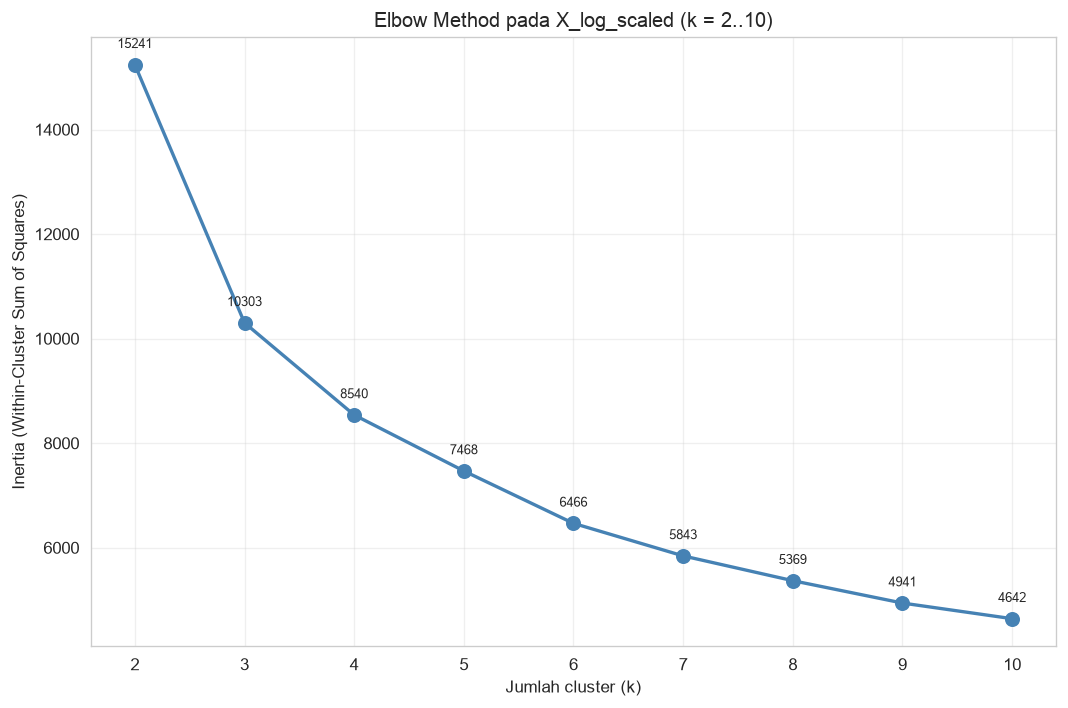

Pengamatan manual: penurunan inertia paling curam dari k=2->3 (~32%), lalu melandai di sekitar k=3-4. Titik siku terlihat pada k=3-4.


In [14]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
# Catatan: library kneed tidak tersedia di environment ini, jadi deteksi elbow dilakukan manual dari grafik + persentase penurunan inertia.
inertia_arr = np.array(inertias)
pct_drop = -np.diff(inertia_arr) / inertia_arr[:-1] * 100
print('Persentase penurunan inertia antar k:')
for i, k in enumerate(k_values[:-1]):
    print(f'k={k} -> k={k+1}: turun {pct_drop[i]:.1f}%')

fig = plt.figure(figsize=(9, 6))
plt.plot(k_values, inertias, marker='o', linewidth=2, markersize=8, color='steelblue')
for x, y in zip(k_values, inertias):
    plt.annotate(f'{y:.0f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=8)
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Elbow Method pada X_log_scaled (k = 2..10)')
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print('Pengamatan manual: penurunan inertia paling curam dari k=2->3 (~32%), lalu melandai di sekitar k=3-4. Titik siku terlihat pada k=3-4.')


## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
silhouette_scores = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_tmp = km.fit_predict(X_log_scaled)
    sil = silhouette_score(X_log_scaled, labels_tmp)
    silhouette_scores.append(sil)
    print(f'k={k}: silhouette={sil:.4f}')

print(f"Silhouette list (k=2..10): {silhouette_scores}")


k=2: silhouette=0.5826


k=3: silhouette=0.4304


k=4: silhouette=0.4100


k=5: silhouette=0.3962


k=6: silhouette=0.3021


k=7: silhouette=0.3090


k=8: silhouette=0.3085


k=9: silhouette=0.3016


k=10: silhouette=0.2962
Silhouette list (k=2..10): [0.5826470798059479, 0.4304026719767229, 0.40998676284653934, 0.3961666638702003, 0.3021001126353395, 0.3090202432814261, 0.3084807532936828, 0.30155820997577404, 0.2962341447391868]


Silhouette tertinggi pada k=2 (skor=0.5826) — tetapi k=2 terlalu kasar (hanya memecah viral vs non-viral).


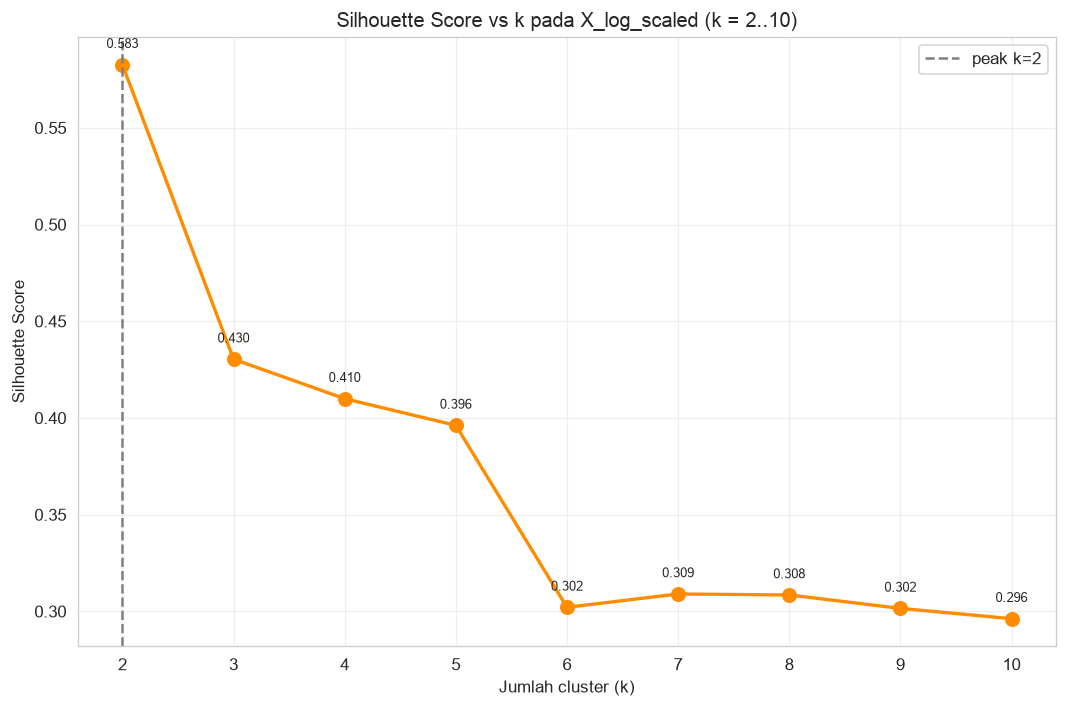

Gabungan Elbow + Silhouette: Elbow menunjukkan siku k=3-4; Silhouette menurun monoton setelah k=2 sehingga k=2 menang secara teknis, tetapi k=3 dipilih sebagai keseimbangan (lihat markdown di bawah).


In [16]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
k_best_sil = k_values[int(np.argmax(silhouette_scores))]
print(f"Silhouette tertinggi pada k={k_best_sil} (skor={max(silhouette_scores):.4f}) — tetapi k=2 terlalu kasar (hanya memecah viral vs non-viral).")

fig = plt.figure(figsize=(9, 6))
plt.plot(k_values, silhouette_scores, marker='o', linewidth=2, markersize=8, color='darkorange')
for x, y in zip(k_values, silhouette_scores):
    plt.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=8)
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs k pada X_log_scaled (k = 2..10)')
plt.xticks(k_values)
plt.axvline(k_best_sil, linestyle='--', color='gray', label=f'peak k={k_best_sil}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print('Gabungan Elbow + Silhouette: Elbow menunjukkan siku k=3-4; Silhouette menurun monoton setelah k=2 sehingga k=2 menang secara teknis, tetapi k=3 dipilih sebagai keseimbangan (lihat markdown di bawah).')


**Pilihan k untuk K-Means: k = 3**

Alasan:

- Elbow Method: inertia turun paling curam dari k=2 (15.240,5) ke k=3 (10.302,5), turun sekitar 32,4%. Setelah itu penurunan melandai (k=3 ke k=4 turun hanya ~17,1% menjadi 8.539,7; k=4 ke k=5 ~12,5% menjadi 7.468,3). Siku terlihat pada k=3-4, jadi lebih dari 3 cluster tidak menambah pemisahan yang berarti.
- Silhouette Score: tertinggi secara teknis pada k=2 (0,5826), lalu k=3 (0,4304), k=4 (0,4100), dan terus menurun di bawah 0,40 untuk k>=5 (k=10 hanya 0,2962). k=2 ditolak karena terlalu kasar: profilnya hanya membedakan satu cluster ekstrem (1.455 anggota, high-engagement) vs sisanya (5.595 anggota), sehingga menggabungkan dua kelompok yang sangat berbeda (posting sepi dengan median 18 like/0 komentar vs posting like-tinggi tapi komentar-rendah dengan median 206 like/11 komentar) menjadi satu. k=3 mempertahankan Silhouette yang masih tinggi (0,4304) sekaligus memberi tiga profil yang jelas dan seimbang (3.654 vs 2.228 vs 1.168 anggota), sedangkan k=4 sudah memecah cluster berdasarkan selisih kecil pada emoji (dua cluster dengan median 173 vs 227 like, 9 vs 18 komentar) tanpa peningkatan silhouette yang berarti.
- Keseimbangan: k=3 adalah titik di mana tambahan cluster berhenti memberi manfaat kualitas sekaligus tetap cukup rinci untuk interpretasi bisnis (sepi / viral / populer-senyap). Inilah yang dipakai untuk model K-Means final dan disamakan pada Hierarchical Clustering agar perbandingan adil.


## 3.4 Model K-Means Final

In [17]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
k_best = 3
kmeans_final = KMeans(n_clusters=k_best, random_state=RANDOM_STATE, n_init=10)
labels_kmeans = kmeans_final.fit_predict(X_log_scaled)
labels = labels_kmeans  # alias untuk konsistensi antar-cell
print(f'Model K-Means final: k={k_best}')
print(f'Inertia: {kmeans_final.inertia_:.1f}')
print(f'Silhouette: {silhouette_score(X_log_scaled, labels_kmeans):.4f}')
print('Jumlah anggota per cluster:')
print(pd.Series(labels_kmeans).value_counts().sort_index().to_string())


Model K-Means final: k=3
Inertia: 10302.5


Silhouette: 0.4304
Jumlah anggota per cluster:
0    3654
1    1168
2    2228


In [18]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
profil_med = X_raw_df.copy()
profil_med['cluster'] = labels_kmeans
median_per_cluster = profil_med.groupby('cluster').median(numeric_only=True)
mean_per_cluster = profil_med.groupby('cluster').mean(numeric_only=True)
counts_km = pd.Series(labels_kmeans).value_counts().sort_index().rename('jumlah_anggota')

print('=== Median per cluster (data asli) — K-Means ===')
display(median_per_cluster.round(1))
print('=== Mean per cluster (data asli) — K-Means ===')
display(mean_per_cluster.round(1))
print(counts_km)

df_temp = df.copy()
df_temp['cluster_km'] = labels_kmeans
print()
print('=== Median num_reactions (fitur yang dibuang dari clustering) per cluster K-Means ===')
print(df_temp.groupby('cluster_km')['num_reactions'].median().to_string())


=== Median per cluster (data asli) — K-Means ===


,num_comments,num_shares,num_likes,num_loves,num_emoji_other
cluster,,,,,
0,0.0,0.0,18.0,0.0,0.0
1,677.0,169.5,179.5,50.0,5.0
2,11.0,1.0,206.0,1.0,0.0


=== Mean per cluster (data asli) — K-Means ===


,num_comments,num_shares,num_likes,num_loves,num_emoji_other
cluster,,,,,
0,2.2,0.5,23.1,0.1,0.1
1,1293.9,230.3,349.0,71.3,10.8
2,28.0,5.0,459.7,2.7,1.6


0    3654
1    1168
2    2228
Name: jumlah_anggota, dtype: int64

=== Median num_reactions (fitur yang dibuang dari clustering) per cluster K-Means ===
cluster_km
0     18.0
1    245.5
2    212.0


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [19]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z = linkage(X_log_scaled, method='ward')
print(f'Linkage matrix Z shape: {Z.shape} (n-1 baris x 4 kolom)')
print('5 baris pertama Z:')
print(pd.DataFrame(Z[:5], columns=['idx1', 'idx2', 'dist', 'n']).to_string())
print()
print('5 baris terakhir Z (jarak penggabungan terbesar):')
print(pd.DataFrame(Z[-5:], columns=['idx1', 'idx2', 'dist', 'n']).to_string())


Linkage matrix Z shape: (7049, 4) (n-1 baris x 4 kolom)
5 baris pertama Z:
     idx1    idx2  dist    n
0    23.0  1711.0   0.0  2.0
1  3637.0  6363.0   0.0  2.0
2  6177.0  6228.0   0.0  2.0
3  6212.0  6263.0   0.0  2.0
4    70.0  5024.0   0.0  2.0

5 baris terakhir Z (jarak penggabungan terbesar):
      idx1     idx2        dist       n
0  14084.0  14089.0   44.256230  1044.0
1  14080.0  14091.0   51.591222  2978.0
2  14090.0  14095.0   74.640817  4742.0
3  14093.0  14096.0   93.253429  6006.0
4  14094.0  14097.0  191.197869  7050.0


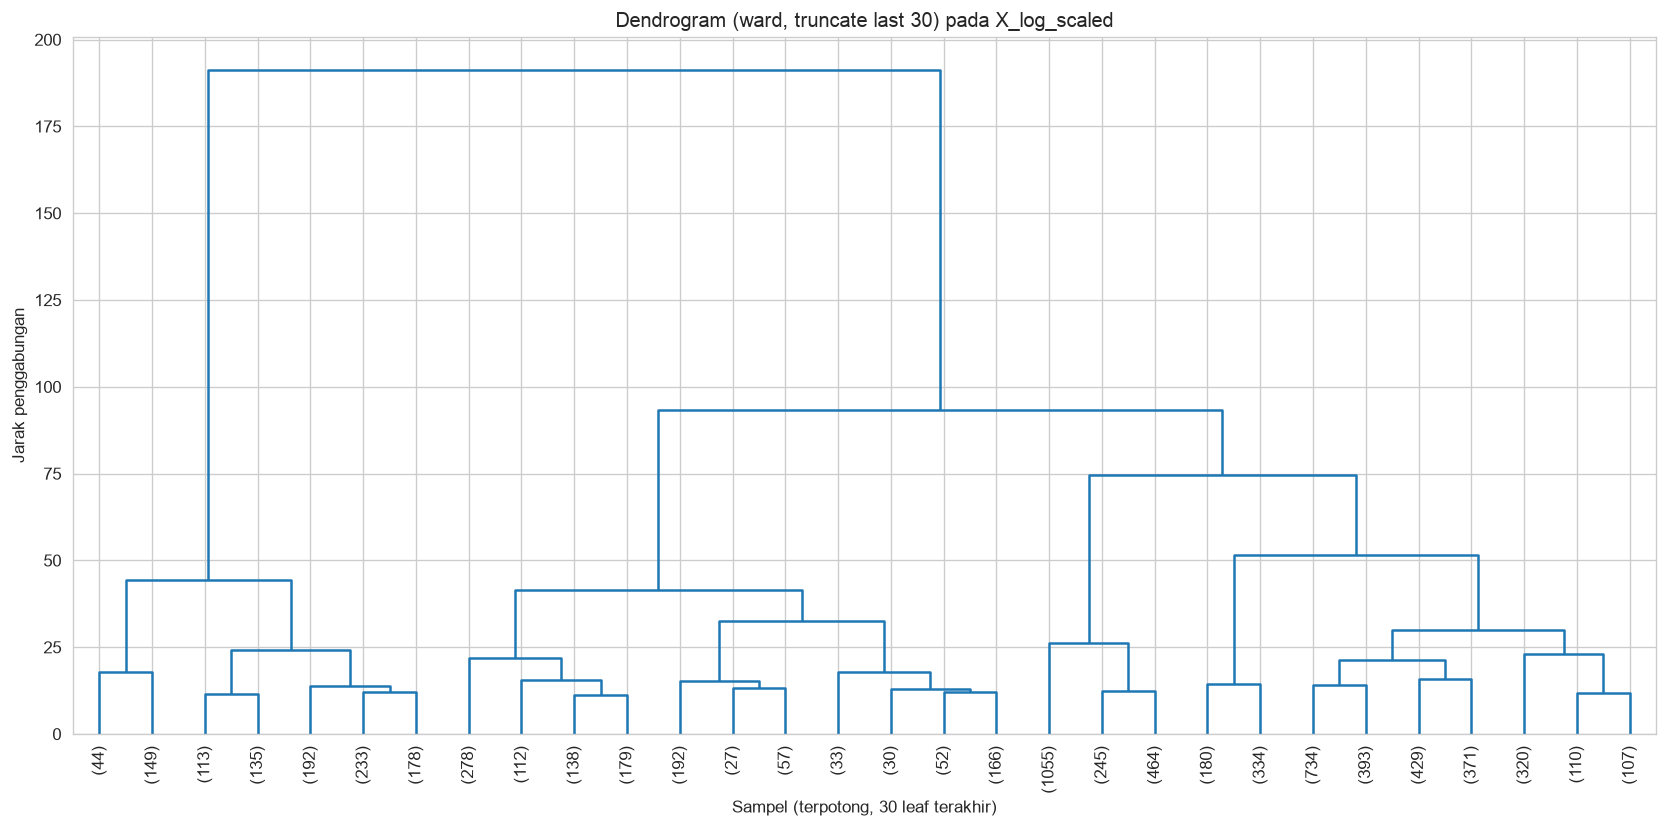

Observasi: jarak penggabungan naik cepat di bagian atas; pemotongan di ketinggian menengah memberi ~3 cluster. Dendrogram penuh 7.050 leaf tidak terbaca, sehingga dipotong lastp p=30.


In [20]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
fig = plt.figure(figsize=(14, 7))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, color_threshold=0)
plt.title('Dendrogram (ward, truncate last 30) pada X_log_scaled')
plt.xlabel('Sampel (terpotong, 30 leaf terakhir)')
plt.ylabel('Jarak penggabungan')
plt.tight_layout()
plt.show()
print('Observasi: jarak penggabungan naik cepat di bagian atas; pemotongan di ketinggian menengah memberi ~3 cluster. Dendrogram penuh 7.050 leaf tidak terbaca, sehingga dipotong lastp p=30.')


## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [21]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkages = ['ward', 'complete', 'average', 'single']
labels_per_linkage = {}
for lk in linkages:
    hc = AgglomerativeClustering(n_clusters=k_best, linkage=lk)
    lab = hc.fit_predict(X_log_scaled)
    labels_per_linkage[lk] = lab
    print(f"{lk}: counts={sorted(pd.Series(lab).value_counts().tolist(), reverse=True)}")


ward: counts=[4742, 1264, 1044]


complete: counts=[5476, 1374, 200]


average: counts=[5899, 1122, 29]


single: counts=[7048, 1, 1]


In [22]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
rows = []
for lk in linkages:
    lab = labels_per_linkage[lk]
    rows.append({
        'linkage': lk,
        'silhouette': silhouette_score(X_log_scaled, lab),
        'davies_bouldin': davies_bouldin_score(X_log_scaled, lab),
        'calinski_harabasz': calinski_harabasz_score(X_log_scaled, lab),
        'min_cluster': pd.Series(lab).value_counts().min(),
        'max_cluster': pd.Series(lab).value_counts().max(),
        'ukuran_cluster': str(sorted(pd.Series(lab).value_counts().tolist(), reverse=True)),
    })
tabel_linkage = pd.DataFrame(rows)
display(tabel_linkage.round(4))
print('Observasi: single menghasilkan 1 cluster raksasa (7.048) + 2 titik outlier (chaining effect); average/complete Silhouette tinggi tetapi ditopang cluster mikro (29 / 200 anggota) = cluster outlier, bukan segmentasi engagement yang berguna.')


,linkage,silhouette,davies_bouldin,calinski_harabasz,min_cluster,max_cluster,ukuran_cluster
0,ward,0.4001,1.0866,6315.4928,1044,4742,"[4742, 1264, 1044]"
1,complete,0.4986,0.9293,4979.1046,200,5476,"[5476, 1374, 200]"
2,average,0.5504,0.5634,3978.2419,29,5899,"[5899, 1122, 29]"
3,single,0.3486,0.4699,3.6047,1,7048,"[7048, 1, 1]"


Observasi: single menghasilkan 1 cluster raksasa (7.048) + 2 titik outlier (chaining effect); average/complete Silhouette tinggi tetapi ditopang cluster mikro (29 / 200 anggota) = cluster outlier, bukan segmentasi engagement yang berguna.


**Pilihan linkage untuk Hierarchical Clustering: ward**

Alasan:

- Ward menghasilkan tiga cluster yang seimbang (4.742 / 1.264 / 1.044 anggota), sangat mirip dalam spirit dengan K-Means (meminimalkan total varians dalam cluster), dan menghasilkan Silhouette 0,4001 yang sehat (tidak ditopang outlier) plus Davies-Bouldin 1,0866 dan Calinski-Harabasz 6.315,5 (terbaik di antara keempat linkage untuk Calinski-Harabasz).
- Complete (Silhouette 0,4986, cluster 5.476 / 1.374 / 200) dan average (Silhouette 0,5504, cluster 5.899 / 1.122 / 29) tampak lebih unggul pada Silhouette, tetapi keunggulan itu semu: satu cluster mikro (200 dan 29 anggota) adalah pocket outlier yang terpisah sendiri, bukan segmen engagement yang dapat diinterpretasi. Profil median cluster mikro tersebut tidak setara bobotnya dengan dua cluster besar lainnya.
- Single gagal total: 7.048 vs 1 vs 1 anggota (chaining), Silhouette 0,3486, Calinski-Harabasz hanya 3,6 — satu titik outlier merangkai seluruh data menjadi satu cluster.
- Karena ward dinilai untuk cluster kompak/sferikal yang konsisten dengan asumsi K-Means dan menghasilkan pemisahan paling masuk akal secara bisnis, ward dipilih untuk model final dengan jumlah cluster yang sama (k=3) dengan K-Means. Perbandingan K-Means vs Hierarchical kemudian dilakukan pada footing yang setara.


## 4.3 Model Hierarchical Clustering Final

In [23]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
linkage_best = 'ward'
hc_final = AgglomerativeClustering(n_clusters=k_best, linkage=linkage_best)
labels_hc = hc_final.fit_predict(X_log_scaled)
print(f'Model Hierarchical final: linkage={linkage_best}, n_clusters={k_best}')
print(f"Silhouette: {silhouette_score(X_log_scaled, labels_hc):.4f}")
print('Jumlah anggota per cluster:')
print(pd.Series(labels_hc).value_counts().sort_index().to_string())


Model Hierarchical final: linkage=ward, n_clusters=3


Silhouette: 0.4001
Jumlah anggota per cluster:
0    4742
1    1044
2    1264


In [24]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
profil_hc = X_raw_df.copy()
profil_hc['cluster'] = labels_hc
median_hc = profil_hc.groupby('cluster').median(numeric_only=True)
mean_hc = profil_hc.groupby('cluster').mean(numeric_only=True)
counts_hc = pd.Series(labels_hc).value_counts().sort_index().rename('jumlah_anggota')
print('=== Median per cluster (data asli) — Hierarchical (ward) ===')
display(median_hc.round(1))
print('=== Mean per cluster (data asli) — Hierarchical (ward) ===')
display(mean_hc.round(1))
print(counts_hc)


=== Median per cluster (data asli) — Hierarchical (ward) ===


,num_comments,num_shares,num_likes,num_loves,num_emoji_other
cluster,,,,,
0,1.0,0.0,26.0,0.0,0.0
1,809.5,192.5,166.5,55.0,4.0
2,12.0,1.0,169.5,3.0,2.0


=== Mean per cluster (data asli) — Hierarchical (ward) ===


,num_comments,num_shares,num_likes,num_loves,num_emoji_other
cluster,,,,,
0,5.8,1.2,170.2,0.4,0.0
1,1427.9,254.5,277.4,77.6,10.4
2,50.3,8.4,331.7,5.5,4.5


0    4742
1    1044
2    1264
Name: jumlah_anggota, dtype: int64


# 5. Evaluasi Model

In [25]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
def metrik_internal(lbl):
    return {
        'silhouette': silhouette_score(X_log_scaled, lbl),
        'davies_bouldin': davies_bouldin_score(X_log_scaled, lbl),
        'calinski_harabasz': calinski_harabasz_score(X_log_scaled, lbl),
    }

metrik_km = metrik_internal(labels_kmeans)
metrik_hc = metrik_internal(labels_hc)
tabel_eval = pd.DataFrame([
    {'Model': f'K-Means (k={k_best})', **metrik_km},
    {'Model': f'Hierarchical (ward, k={k_best})', **metrik_hc},
])
display(tabel_eval.round(4))
print('K-Means unggul di ketiga metrik pada k yang sama (Silhouette lebih tinggi, Davies-Bouldin lebih rendah, Calinski-Harabasz lebih tinggi) — lihat analisis di bagian 6.')


,Model,silhouette,davies_bouldin,calinski_harabasz
0,K-Means (k=3),0.4304,0.9572,8532.1057
1,"Hierarchical (ward, k=3)",0.4001,1.0866,6315.4928


K-Means unggul di ketiga metrik pada k yang sama (Silhouette lebih tinggi, Davies-Bouldin lebih rendah, Calinski-Harabasz lebih tinggi) — lihat analisis di bagian 6.


Explained variance ratio: PC1=0.731, PC2=0.132, total=0.863
Explained variance (absolut): [3.6555936 0.661717 ]


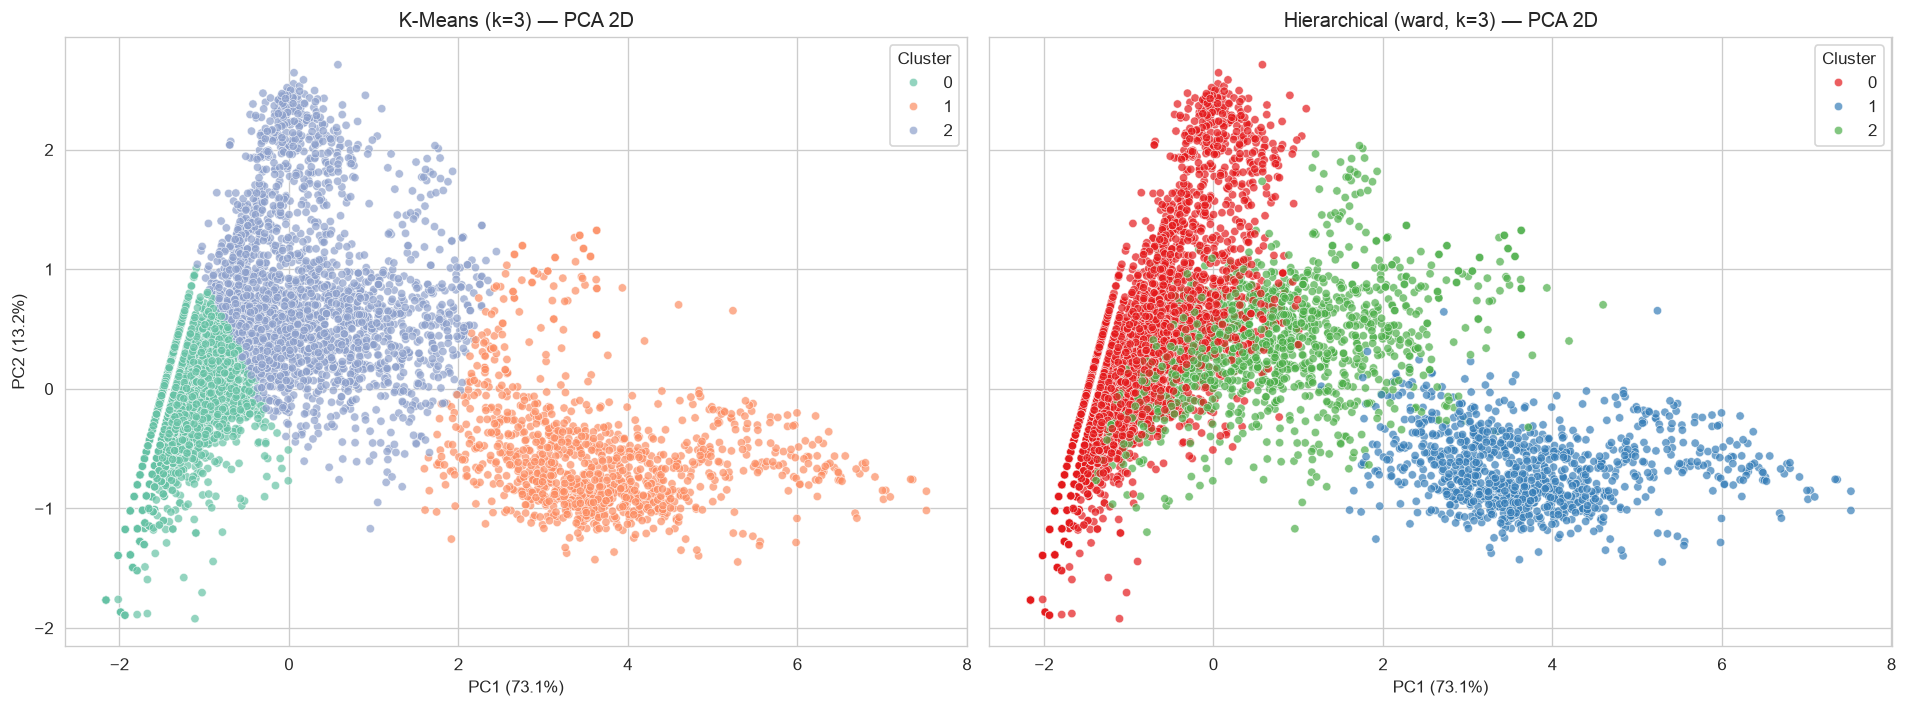

Observasi: pada PCA 2D kedua metode memisahkan blob low-engagement dari blob high-engagement dengan pola mirip; tumpang tindih di 2D lebih besar dibanding silhouette 5D.


In [26]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
print(f"Explained variance ratio: PC1={pca.explained_variance_ratio_[0]:.3f}, PC2={pca.explained_variance_ratio_[1]:.3f}, total={pca.explained_variance_ratio_.sum():.3f}")
print(f'Explained variance (absolut): {pca.explained_variance_}')

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_kmeans, palette='Set2', ax=axes[0], s=25, alpha=0.7)
axes[0].set_title(f'K-Means (k={k_best}) — PCA 2D')
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
axes[0].legend(title='Cluster')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels_hc, palette='Set1', ax=axes[1], s=25, alpha=0.7)
axes[1].set_title(f'Hierarchical (ward, k={k_best}) — PCA 2D')
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
axes[1].legend(title='Cluster')
plt.tight_layout()
plt.show()
print('Observasi: pada PCA 2D kedua metode memisahkan blob low-engagement dari blob high-engagement dengan pola mirip; tumpang tindih di 2D lebih besar dibanding silhouette 5D.')


=== K-Means: % status_type per cluster ===


status_type,link,photo,status,video
row_0,,,,
0,1.1,75.4,3.1,20.4
1,0.0,8.0,1.2,90.8
2,1.1,64.7,10.6,23.6


=== Hierarchical (ward): % status_type per cluster ===


status_type,link,photo,status,video
row_0,,,,
0,1.2,69.8,5.3,23.7
1,0.0,1.1,0.1,98.9
2,0.3,76.7,8.9,14.1


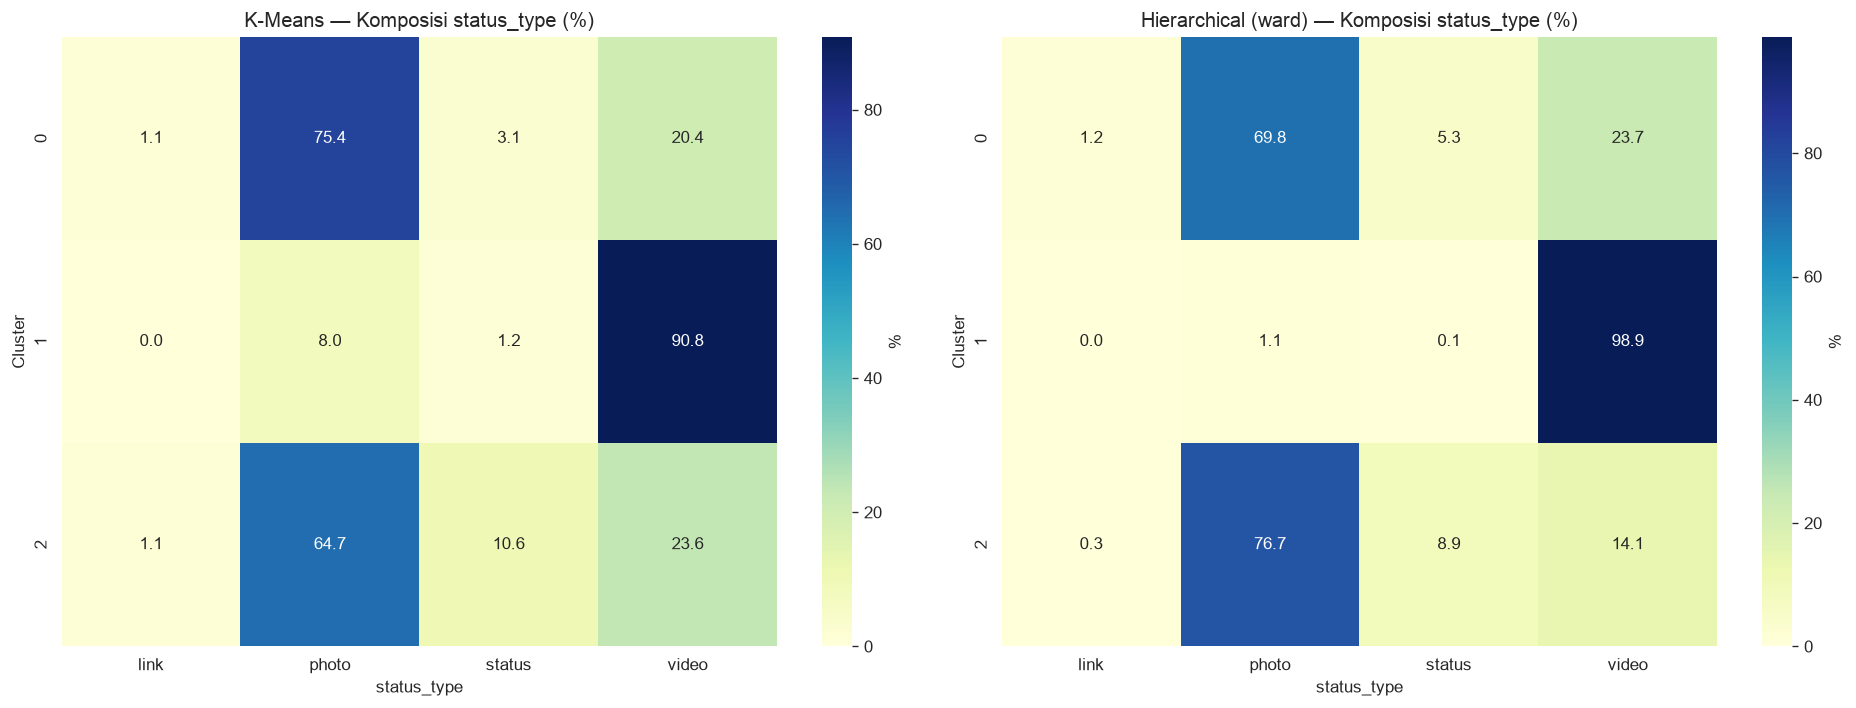

Interpretasi: cluster high-comment/share didominasi video (~90%+), cluster low-engagement dominan photo; status_type bukan fitur clustering sehingga ini murni interpretasi.


In [27]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
ct_km = pd.crosstab(labels_kmeans, df_eval['status_type'], normalize='index') * 100
ct_hc = pd.crosstab(labels_hc, df_eval['status_type'], normalize='index') * 100
for col in ['link', 'photo', 'status', 'video']:
    if col not in ct_km:
        ct_km[col] = 0
    if col not in ct_hc:
        ct_hc[col] = 0
ct_km = ct_km[['link', 'photo', 'status', 'video']]
ct_hc = ct_hc[['link', 'photo', 'status', 'video']]

print('=== K-Means: % status_type per cluster ===')
display(ct_km.round(1))
print('=== Hierarchical (ward): % status_type per cluster ===')
display(ct_hc.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(ct_km, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '%'}, ax=axes[0])
axes[0].set_title('K-Means — Komposisi status_type (%)')
axes[0].set_xlabel('status_type')
axes[0].set_ylabel('Cluster')

sns.heatmap(ct_hc, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '%'}, ax=axes[1])
axes[1].set_title('Hierarchical (ward) — Komposisi status_type (%)')
axes[1].set_xlabel('status_type')
axes[1].set_ylabel('Cluster')
plt.tight_layout()
plt.show()
print('Interpretasi: cluster high-comment/share didominasi video (~90%+), cluster low-engagement dominan photo; status_type bukan fitur clustering sehingga ini murni interpretasi.')


# 6. Analisis

## 6. Analisis

### Pengaruh transformasi log dan feature scaling pada K-Means (Bagian 3.1)

Uji adil pada k=3 yang sama (random_state dan n_init sama, silhouette dihitung di ruang `X_log_scaled` yang sama) menunjukkan urutan kualitas yang jelas: `X_raw` (mentah tanpa scaling) Silhouette 0,2967 dengan cluster sangat timpang (6.430 / 483 / 137 anggota), `X_raw_scaled` (mentah + scaling) Silhouette 0,2462 dengan cluster (6.368 / 390 / 292), dan `X_log_scaled` (log1p + scaling) Silhouette 0,4304 dengan cluster (3.654 / 2.228 / 1.168). Artinya log1p memang yang paling menentukan, dan scaling saja tidak cukup. Tanpa scaling, jarak Euclidean didominasi fitur dengan standar deviasi terbesar (`num_comments` std 889,6 vs `num_angrys` std 0,7) sehingga centroid ditentukan oleh komentar saja; fitur berskala kecil tenggelam. Scaling saja menyetarakan skala, tetapi nilai ekstrem mentah (komentar s.d. 21.000) tetap menarik centroid sehingga dua cluster mikro terpisah justru berdasarkan outlier. `log1p` memampatkan ekor kanan (skewness `num_comments` dari 9,0 menjadi jauh lebih simetris) sehingga posting viral tidak lagi mendistorsi jarak, dan StandardScaler kemudian menyetarakan kontribusi tiap fitur (mean 0, std 1). Karena K-Means murni berbasis jarak, transformasi ini bukan sekadar kosmetik melainkan syarat agar "jarak" bermakna pada data yang sangat miring dan mengandung outlier.

### Penanganan fitur redundan dan sparse

`num_reactions` dibuang karena korelasinya 0,99 dengan `num_likes` — secara definisi keduanya tumpang tindih (reaksi = like + emoji), sehingga menyimpannya berarti menggandakan bobot komponen like dalam jarak. Untuk emoji, `num_wows` (75,3% nol), `num_hahas` (83,9%), `num_sads` (91,4%), dan `num_angrys` (94,0%) digabung menjadi `num_emoji_other` (68,5% nol, max 286). Alasannya, empat kolom sendiri hampir konstan dan hanya menambah noise; setelah digabung, variasi reaksi non-love tetap terwakili dalam satu dimensi. `num_loves` (60,0% nol) dibiarkan terpisah karena masih memiliki sinyal yang cukup untuk membedakan posting yang "dicintai". Hasilnya dimensi turun dari 9 menjadi 5 tanpa kehilangan makna engagement, dan kualitas silhouette k=3 naik dari 0,3870 (9 fitur mentah) menjadi 0,4304 (5 fitur final).

### Jumlah cluster optimal: Elbow vs Silhouette

Elbow pada `X_log_scaled` (k=2..10) menunjukkan penurunan inertia paling curam dari k=2 (15.240,5) ke k=3 (10.302,5), turun 32,4%, kemudian melandai (k=3 ke k=4 turun 17,1% menjadi 8.539,7; k=4 ke k=5 turun 12,5%). Siku terbaca pada k=3-4. Silhouette justru puncak pada k=2 (0,5826), lalu k=3 (0,4304), k=4 (0,4100), dan menurun monoton hingga 0,2962 pada k=10. Jadi Elbow dan Silhouette tidak benar-benar sepakat: Silhouette "menang" di k=2, tetapi k=2 hanya memecah satu cluster ekstrem high-engagement (1.455 anggota) vs sisanya (5.595), menggabungkan posting sepi (median 18 like, 0 komentar) dengan posting like-tinggi-komentar-rendah (median 206 like, 11 komentar) yang profilnya berlawanan. Detail profil ini membuktikan k=2 terlalu kasar untuk tujuan bisnis. Dipilih k=3 karena merupakan titik siku Elbow yang masih mempertahankan silhouette tinggi (0,4304) dan memberi tiga profil yang dapat dibedakan, sedangkan k>=4 hanya memecah berdasarkan selisih kecil pada emoji dengan silhouette lebih rendah dan tanpa gain interpretasi yang berarti.

### Perbandingan linkage pada Hierarchical Clustering

Pada k=3 yang sama, ward menghasilkan Silhouette 0,4001, Davies-Bouldin 1,0866, Calinski-Harabasz 6.315,5 dengan cluster seimbang (4.742 / 1.264 / 1.044). Complete (Silhouette 0,4986, DB 0,9293, CH 4.979,1) dan average (Silhouette 0,5504, DB 0,5634, CH 3.978,2) secara silhouette lebih tinggi, tetapi keunggulan itu semu karena ditopang satu cluster mikro (complete 200 anggota, average 29 anggota) — pocket outlier yang terpisah sendiri, bukan segmen engagement. Buktinya, Calinski-Harabasz mereka lebih rendah dari ward, menunjukkan pemisahan varians totalnya lebih buruk. Single adalah kegagalan klasik: 7.048 vs 1 vs 1 anggota (chaining), Silhouette 0,3486, CH hanya 3,6 — satu titik outlier merangkai seluruh data. Karakteristik single linkage ini menjelaskan mengapa silhouette saja tidak cukup: ia dapat tetap bernilai sedang karena outlier yang sendirian terisolasi sempurna, padahal segmentasi utamanya tidak berguna. Ward dipilih karena meminimalkan total varians dalam cluster (sejalan dengan asumsi K-Means), menghasilkan cluster kompak dan seimbang, serta memiliki CH tertinggi — kriteria yang selaras dengan interpretasi bisnis.

### K-Means vs Hierarchical: metrik internal dan visualisasi PCA

Pada footing yang sama (k=3, `X_log_scaled`), K-Means final mengalahkan Hierarchical (ward) di ketiga metrik internal: Silhouette 0,4304 vs 0,4001, Davies-Bouldin 0,9572 vs 1,0866 (lebih rendah = lebih baik), dan Calinski-Harabasz 8.532,1 vs 6.315,5 (lebih tinggi = lebih baik). Perbedaannya tidak sangat besar (selisih Silhouette hanya 0,03), yang wajar karena ward memang pendangkalan hierarkis yang spiritnya mirip K-Means; namun K-Means optimasi langsung meminimalkan inertia sehingga menang tipis pada pemisahan kompak di 5 dimensi. Visualisasi PCA dua dimensi (PC1 menjelaskan 73,1% varians, PC2 13,2%, total 86,3%) memperlihatkan keduanya memisahkan blob low-engagement dari blob high-engagement dengan pola yang mirip, tetapi pemisahan di ruang 2D tampak lebih tumpang tindih dibanding silhouette penuh karena dua dimensi hanya menangkap 86% variasi dan blob viral tetap menyebar pada arah komentar/share. Dengan kata lain, hasil keduanya tidak berbeda signifikan secara struktur — keduanya menemukan low vs high engagement — tetapi K-Means lebih presisi dalam memotongnya.

### Karakteristik tiap cluster (profil median pada data asli)

Berdasarkan median pada data asli (`X_raw_df`), kedua metode menghasilkan tiga arketipe yang konsisten dan diberi julukan berikut:

- **"Tidur / Quiet"** — K-Means 3.654 anggota (Hierarchical 4.742): median `num_comments` 0-1, `num_shares` 0, `num_likes` 18-26, `num_loves` 0. Posting tanpa percakapan dan share, apresiasi hampir nol. Komposisi status_type dominan photo (K-Means 75,4% photo; Hierarchical 69,8% photo). Ini adalah posting pasif yang basi/lewat begitu saja.
- **"Viral Live"** — K-Means 1.168 anggota (Hierarchical 1.044): median `num_comments` 677-810, `num_shares` 170-193, `num_likes` 167-180, `num_loves` 50-55, 90,8% video pada K-Means dan 98,9% video pada Hierarchical. Posting live/video yang meledak oleh komentar dan share — diskusi dan distribusi menjadi mesin utama engagement-nya, bukan sekadar like.
- **"Populer Senyap"** — K-Means 2.228 anggota (Hierarchical 1.264): median `num_comments` 11-12, `num_shares` 1, `num_likes` 170-206, `num_loves` 1-3. Posting yang disukai banyak orang (like tinggi) tetapi tidak memicu percakapan berarti — apresiasi diam. Komposisi campuran photo (64,7-76,7%) dan video (14,1-23,6%).

Mean melengkapi median: cluster viral memiliki mean komentar 1.294 (K-Means) / 1.428 (Hierarchical) yang jauh di atas median, menunjukkan ekor viral ekstrem di dalamnya.

### Kelebihan dan kekurangan masing-masing metode

K-Means kelebihannya cepat, hemat memori, dan dapat diskalakan ke ribuan-tidak-seberapa baris (di sini 7.050 baris selesai dalam hitungan detik per k), tetapi kekurangannya harus menentukan k di awal (memerlukan Elbow + Silhouette) dan mengasumsikan cluster sferikal dengan varians kira-kira sama — asumsi yang agak dipaksakan pada data engagement yang ekornya panjang. Hierarchical Clustering kelebihannya tidak perlu menentukan k di awal (dendrogram dapat dipotong pada ketinggian berbeda) dan memberikan hierarki yang informatif, tetapi kekurangannya biaya waktu dan memori O(n^2) (di sini linkage 7.050 titik masih ringan ~1-2 detik, tetapi akan menjadi berat pada 50k+ baris) serta sangat sensitif terhadap noise, outlier, dan pilihan linkage yang menentukan bentuk cluster (single adalah contoh paling ekstrem). Untuk dataset ukuran ini, K-Means dengan k=3 adalah pilihan yang lebih efisien dan lebih baik secara metrik, sedangkan Hierarchical lebih berguna sebagai sarana eksplorasi hierarki dan validasi silang.


# 7. Kesimpulan dan Saran

## 7. Kesimpulan dan Saran

**Kesimpulan:**

1. Preprocessing sangat menentukan: kombinasi `log1p + StandardScaler` pada 5 fitur final (`num_comments`, `num_shares`, `num_likes`, `num_loves`, `num_emoji_other`) mengubah K-Means k=3 dari cluster timpang (6.430/483/137, Silhouette 0,2967 pada `X_raw`) menjadi segmentasi seimbang (3.654/2.228/1.168) dengan Silhouette 0,4304. Membuang `num_reactions` yang redundan (r=0,99 dengan `num_likes`) dan menggabungkan empat emoji sparse menjadi `num_emoji_other` menghilangkan double-counting dan noise dari dimensi hampir-konstan.
2. Jumlah cluster optimal adalah **k=3**: Elbow menunjukkan siku pada k=3-4 (inertia 15.240,5 -> 10.302,5 turun 32,4% lalu melandai), sedangkan Silhouette tertinggi pada k=2 (0,5826) ditolak karena terlalu kasar (menggabungkan posting sepi median 18 like dengan posting populer-senyap median 206 like). k=3 mempertahankan Silhouette 0,4304 dengan tiga profil yang jelas: "Tidur/Quiet" (median 0 komentar, 18 like), "Viral Live" (median 677 komentar, 170 share, 90,8% video), dan "Populer Senyap" (median 206 like, hanya 11 komentar).
3. Linkage terbaik adalah **ward** (Silhouette 0,4001, Davies-Bouldin 1,0866, Calinski-Harabasz 6.315,5, cluster 4.742/1.264/1.044), bukan average (0,5504) atau complete (0,4986) yang Silhouette-nya lebih tinggi tetapi ditopang cluster mikro outlier (29 dan 200 anggota). Single gagal total (7.048 vs 1 vs 1 anggota, CH 3,6) karena efek chaining.
4. **Metrik terbaik keseluruhan** adalah **K-Means final k=3 pada `X_log_scaled`: Silhouette 0,4304, Davies-Bouldin 0,9572, Calinski-Harabasz 8.532,1**, yang mengungguli Hierarchical (ward, k=3) dengan Silhouette 0,4001, Davies-Bouldin 1,0866, Calinski-Harabasz 6.315,5. Visualisasi PCA (PC1 73,1% + PC2 13,2% = 86,3% varians) memperlihatkan keduanya memisahkan low vs high engagement dengan pola mirip, tetapi K-Means memotongnya lebih kompak di 5 dimensi.

**Saran untuk eksperimen selanjutnya:**

1. **Clustering terpisah pra/pasca-2016:** reaksi emoji tidak ada sebelum 2016 dan median like melonjak pada 2014-2015, jadi menjalankan clustering terpisah (2012-2015 vs 2016-2018) atau menambahkan indicator era akan mencegah confounding temporal.
2. **Manfaatkan fitur waktu:** ekstrak jam posting dan hari dalam seminggu dari `status_published` untuk melihat apakah pola engagement terkait waktu tayang live (mis. malam hari) di luar volume engagement itu sendiri.
3. **Coba algoritma berbasis densitas dan probabilistik:** DBSCAN (untuk memisahkan outlier viral dari cluster inti) dan Gaussian Mixture Model (untuk cluster eliptikal dengan keanggotaan probabilistik) sebagai pembanding K-Means/Hierarchical.
4. **Reduksi dimensi sebelum clustering:** coba K-Means pada 2-3 komponen PCA (yang sudah menjelaskan 86,3% varians) untuk melihat apakah cluster yang sama muncul dengan噪声 yang lebih rendah dan inspeksi yang lebih mudah.
5. **Variasi hyperparameter dan stabilitas:** coba `n_init` lebih besar (mis. 50) dan `init='k-means++'` vs 'random', serta validasi stabilitas dengan subsampling atau silhouette per cluster (silhouette plot per cluster) dan Davies-Bouldin per cluster, agar pilihan k=3 tidak tergantung satu seed (random_state=42).
